# Antimalarial Random Forest Model — RF-1 (Avalon + 5 Descriptors)
## Replication of: *Kore et al., BMC Chemistry, 2025* — https://doi.org/10.1186/s13065-025-01395-4

**Feature matrix:** Avalon MFP (1024 bits) **concatenated** with 5 physicochemical descriptors:
| # | Descriptor | Source |
|---|-----------|--------|
| 1 | **MW** — Molecular Weight | OpenChemLib |
| 2 | **TPSA** — Topological Polar Surface Area | OpenChemLib |
| 3 | **cLogP** — Calculated partition coefficient | OpenChemLib |
| 4 | **AromaticRings** — Number of aromatic rings | OpenChemLib |
| 5 | **BaN** — Basic Nitrogen count | OpenChemLib (pKa-based port of AtomFunctionAnalyzer) |

**Input:** Pre-split CSV files (train / validation / test) — no ChEMBL fetch or re-splitting needed.

> **Descriptor backend:** OpenChemLib-JS (via Node.js subprocess). All 5 descriptors are calculated
> using `openchemlib` npm package — no DataWarrior required. BaN uses the exact port of
> `AtomFunctionAnalyzer.isBasicNitrogen()` from the OpenChemLib Java source (pKa > 7 estimate).


## 0. Install Dependencies

In [2]:
from google.colab import drive
drive.mount('/content/drive')

# Set this at the top of EVERY notebook
PROJECT_DIR = '/content/drive/MyDrive/antimalarial_project/'

# Then use it for every file
rf_model_path    = PROJECT_DIR + 'rf_model.pkl'
actives_path     = PROJECT_DIR + 'clean_actives.pkl'
log_zs_path      = PROJECT_DIR + 'log_zero_shot.jsonl'
# etc.

Mounted at /content/drive


In [3]:
import subprocess, sys
for pkg in ["rdkit", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "tqdm"]:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

# Install openchemlib-JS via npm (used for descriptor calculation)
subprocess.run(['npm', 'install', 'openchemlib', '--prefix', '/tmp/ocl'],
               check=True, capture_output=True)
print("All packages installed (including openchemlib-JS).")


All packages installed (including openchemlib-JS).


## 1. Imports

In [4]:
import warnings
warnings.filterwarnings('ignore')

import subprocess, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from tqdm.notebook import tqdm
import pickle, os

# RDKit — only for Avalon fingerprints and SMILES validation
from rdkit import Chem, DataStructs

# Avalon
try:
    from rdkit.Avalon import pyAvalonTools
    AVALON_AVAILABLE = True
    print("Avalon fingerprints available")
except ImportError:
    AVALON_AVAILABLE = False
    print("WARNING: Avalon not available. Falling back to RDKit topological FP.")

# Scikit-learn
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, matthews_corrcoef,
    cohen_kappa_score, confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import cdist

print("All imports successful")


Avalon fingerprints available
All imports successful


In [5]:
# ── Run this diagnostic before anything else ─────────────

import os
from google.colab import drive

# Step 1: Mount Drive
drive.mount('/content/drive')

# Step 2: Define PROJECT_DIR
PROJECT_DIR = '/content/drive/MyDrive/antimalarial_project/'

# Step 3: Create folder if it doesn't exist yet
os.makedirs(PROJECT_DIR, exist_ok=True)

# Step 4: Confirm everything is in order
print(f"PROJECT_DIR  : {PROJECT_DIR}")
print(f"Drive mounted: {os.path.exists('/content/drive/MyDrive/')}")
print(f"Folder exists: {os.path.exists(PROJECT_DIR)}")

# Step 5: Define save_fig so it's available for every plot cell below
import matplotlib.pyplot as plt

def save_fig(filename, dpi=150):
    path = PROJECT_DIR + filename
    plt.savefig(path, dpi=dpi, bbox_inches='tight')
    print(f"Saved to Drive: {path}")

# Step 6: Quick write test — confirms you actually have write permission
test_path = PROJECT_DIR + '_write_test.txt'
with open(test_path, 'w') as f:
    f.write('ok')
os.remove(test_path)
print("Write permission: OK")
print("\nAll good. Run your notebook cells now.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PROJECT_DIR  : /content/drive/MyDrive/antimalarial_project/
Drive mounted: True
Folder exists: True
Write permission: OK

All good. Run your notebook cells now.


In [6]:
def save_fig(filename):
    path = PROJECT_DIR + filename
    plt.savefig(path, dpi=150, bbox_inches='tight')
    print(f"Plot saved to Drive: {path}")

## 2. Configuration
**Edit this cell to match your CSV files and column names.**

In [7]:
import os

# ============================================================
#  EDIT THESE to match your files
# ============================================================

TRAIN_CSV  = "train.csv"        # 60% — used for RF training
VAL_CSV    = "validation.csv"   # 20% — used for hyperparameter optimisation
TEST_CSV   = "test.csv"         # 20% — held-out external test set

SMILES_COL = "Molecule (RDKit Mol) (Canonical)"  # Column with SMILES strings
LABEL_COL  = "Category"                           # Activity: 1 = active, 0 = inactive

# NOTE: BaN is now calculated automatically via OpenChemLib-JS.
# No BAN_COL or DataWarrior CSV needed.

AVALON_NBITS = 1024   # Paper used 1024

# ============================================================
print(f"Train CSV  : {TRAIN_CSV}")
print(f"Val CSV    : {VAL_CSV}")
print(f"Test CSV   : {TEST_CSV}")
print(f"SMILES col : {SMILES_COL}")
print(f"Label col  : {LABEL_COL}")
print(f"Avalon bits: {AVALON_NBITS}")
print(f"Descriptor backend: OpenChemLib-JS (Node.js)")


Train CSV  : train.csv
Val CSV    : validation.csv
Test CSV   : test.csv
SMILES col : Molecule (RDKit Mol) (Canonical)
Label col  : Category
Avalon bits: 1024
Descriptor backend: OpenChemLib-JS (Node.js)


## 3. Load Pre-Split CSV Files

In [8]:
def load_csv(path, label):
    df = pd.read_csv(path)
    print(f"{label:20s}: {len(df):,} rows  |  columns: {list(df.columns)}")
    return df

train_df = load_csv(TRAIN_CSV, "Training set")
val_df   = load_csv(VAL_CSV,   "Validation set")
test_df  = load_csv(TEST_CSV,  "External test set")

# Validate required columns
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    for col in [SMILES_COL, LABEL_COL]:
        assert col in df.columns, f"Column '{col}' not found in {name} CSV!"

# Class distribution
print("\nClass distribution:")
for name, df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    vc = df[LABEL_COL].value_counts().sort_index()
    print(f"  {name:8s}: Active={vc.get(1,0):,}  Inactive={vc.get(0,0):,}  Total={len(df):,}")


Training set        : 9,070 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']
Validation set      : 3,024 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']
External test set   : 3,024 rows  |  columns: ['Category', 'Molecule (RDKit Mol) (Canonical)']

Class distribution:
  Train   : Active=4,847  Inactive=4,223  Total=9,070
  Val     : Active=1,616  Inactive=1,408  Total=3,024
  Test    : Active=1,616  Inactive=1,408  Total=3,024


## 4. Descriptor Calculation

### Feature Vector = Avalon FP (1024 bits) + 5 Descriptors = 1029 features

The 5 continuous descriptors are calculated using **OpenChemLib-JS** (Node.js subprocess)  
and **z-score standardised** using a scaler fitted on the training set only,  
then concatenated with the binary Avalon bits.

### BaN (Basic Nitrogen) — OpenChemLib pKa-based method
The `basicNitrogenCount` is a line-by-line port of `AtomFunctionAnalyzer.isBasicNitrogen()`  
from the OpenChemLib Java source (Actelion Pharmaceuticals Ltd., BSD-3 licence).  
It counts N atoms with estimated **pKa > 7**, including aliphatic amines, imines, and  
aromatic ring N enabled by ortho/para donors (e.g. 4-aminopyridine).  
Excluded: anilines, unactivated pyridine, amides, sulfonamides, pyrrole-type N, nitriles.

| Descriptor | OpenChemLib property |
|------------|---------------------|
| MW | `MolecularFormula.relativeWeight` |
| TPSA | `MoleculeProperties.polarSurfaceArea` |
| cLogP | `MoleculeProperties.logP` |
| AromaticRings | `Molecule.getAromaticRingCount()` |
| BaN | port of `AtomFunctionAnalyzer.isBasicNitrogen()` |


In [9]:
# ── OpenChemLib-JS descriptor calculation ──────────────────────────────────
# basicNitrogenCount is a line-by-line port of:
#   AtomFunctionAnalyzer.isBasicNitrogen(StereoMolecule mol, int atom)
# from the OpenChemLib Java source (Actelion Pharmaceuticals Ltd., BSD-3 licence).

_OCL_LIB = '/tmp/ocl/node_modules/openchemlib/dist/openchemlib.js'

_OCL_JS_SCRIPT = r"""
import OCL from '""" + _OCL_LIB + r"""';
const { Molecule, MoleculeProperties } = OCL;

function getFakeOxoCount(mol, atom) {
  let n = 0;
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    const no = mol.getAtomicNo(mol.getConnAtom(atom, i));
    if (mol.getConnBondOrder(atom, i) === 2 && (no===7||no===8||no===16)) n++;
  }
  return n;
}

function isStabilized(mol, atom, twice) {
  let found = false;
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    const bond = mol.getConnBond(atom, i);
    if (!mol.isAromaticBond(bond) && mol.getConnBondOrder(atom, i) === 1) {
      const conn = mol.getConnAtom(atom, i);
      if (!mol.isAromaticAtom(conn) &&
          ((mol.getAtomicNo(conn)===6 && getFakeOxoCount(mol,conn)===1) ||
           (mol.getAtomicNo(conn)===16 && getFakeOxoCount(mol,conn)===2))) {
        if (found || !twice) return true;
        found = true;
      }
    }
  }
  return false;
}

function isVinylogFakeOxo(mol, atom) {
  for (let i = 0; i < mol.getConnAtoms(atom); i++) {
    if (mol.getConnBondOrder(atom, i) !== 1) {
      const conn = mol.getConnAtom(atom, i);
      for (let j = 0; j < mol.getConnAtoms(conn); j++)
        if (mol.getConnBondOrder(conn,j)===1 && getFakeOxoCount(mol,mol.getConnAtom(conn,j))!==0)
          return true;
    }
  }
  return false;
}

function isBasicNitrogen(mol, atom) {
  if (mol.getAtomicNo(atom) !== 7) return false;
  if (mol.getAtomCharge(atom) !== 0) return false;
  if (mol.getConnAtoms(atom) + mol.getAtomPi(atom) > 3) return false;
  if (mol.isAromaticAtom(atom)) {
    if (mol.getAtomPi(atom) !== 1) return false;
    if (mol.getAtomRingCount(atom, 7) !== 1) return false;
    const rc = mol.getRingSet();
    for (let r = 0; r < rc.getSize(); r++) {
      if (!rc.isAtomMember(r, atom)) continue;
      const sz = rc.getRingSize(r);
      if (sz !== 5 && sz !== 6) { break; }
      const ring = rc.getRingAtoms(r);
      const R = Array.from({length:sz}, (_,i)=>ring[i]);
      let ni = R.indexOf(atom);
      let opi, mi;
      if (sz === 5) {
        opi = [R[ni-1<0?ni+4:ni-1], R[ni-4<0?ni+1:ni-4]];
        mi  = [R[ni-2<0?ni+3:ni-2], R[ni-3<0?ni+2:ni-3]];
      } else {
        opi = [R[ni-1<0?ni+5:ni-1], R[ni-3<0?ni+3:ni-3], R[ni-5<0?ni+1:ni-5]];
        mi  = [R[ni-2<0?ni+4:ni-2], R[ni-4<0?ni+2:ni-4]];
      }
      let ec = 0;
      for (let i=0; i<R.length; i++)
        if (atom!==R[i] && mol.getAtomicNo(R[i])===7 && mol.getAtomPi(R[i])===1) ec--;
      for (let i=0; i<opi.length; i++) {
        let exoAtom=-1, exoBond=-1;
        for (let j=0; j<mol.getConnAtoms(opi[i]); j++) {
          if (!mol.isAromaticBond(mol.getConnBond(opi[i],j))) {
            exoAtom=mol.getConnAtom(opi[i],j); exoBond=mol.getConnBond(opi[i],j); break;
          }
        }
        if (exoAtom !== -1) {
          if (mol.getAtomicNo(exoAtom)===7 && mol.getAtomPi(exoAtom)===0
              && (mol.getConnAtoms(exoAtom)+mol.getAtomPi(exoAtom)<=3)
              && !isStabilized(mol,exoAtom,false)) { ec++; continue; }
          if (mol.getAtomicNo(exoAtom)===8 && mol.getConnAtoms(exoAtom)===1) { ec+=2; continue; }
          if (mol.isAromaticBond(exoBond)) {
            for (let s=0; s<rc.getSize(); s++) {
              if (rc.isAromatic(s) && rc.isAtomMember(s,exoAtom)) {
                const ra=rc.getRingAtoms(s);
                for (let j=0; j<rc.getRingSize(s); j++)
                  if (mol.getAtomicNo(ra[j])===7 && mol.getAtomPi(ra[j])===1) { ec--; break; }
                break;
              }
            }
          }
        }
      }
      for (let i=0; i<mi.length; i++) {
        let exoAtom=-1;
        for (let j=0; j<mol.getConnAtoms(mi[i]); j++)
          if (!mol.isAromaticBond(mol.getConnBond(mi[i],j))) exoAtom=mol.getConnAtom(mi[i],j);
        if (mol.getAtomicNo(mi[i])===6) {
          if (exoAtom!==-1 && getFakeOxoCount(mol,exoAtom)!==0) ec--;
        } else if (mol.getAtomicNo(mi[i])===7) {
          if (mol.getAtomPi(mi[i])===0 &&
              (exoAtom===-1 || (!mol.isAromaticAtom(exoAtom) && getFakeOxoCount(mol,exoAtom)===0)))
            ec++;
        }
      }
      return ec > 0;
    }
    return false;
  }
  if (mol.getAtomPi(atom) > 1) return false;
  if (mol.getAtomPi(atom) === 1) {
    let imineC=-1, sc=0;
    for (let i=0; i<mol.getConnAtoms(atom); i++) {
      const conn=mol.getConnAtom(atom,i);
      if (mol.getConnBondOrder(atom,i)===2) {
        if (mol.getAtomicNo(conn)!==6) return false;
        imineC=conn; continue;
      }
      if (mol.getAtomicNo(conn)===8) return false;
      if (mol.getAtomicNo(conn)===7) { sc--; if (isStabilized(mol,conn,false)) sc--; continue; }
      if (mol.isAromaticAtom(conn)) sc--;
    }
    if (imineC===-1) return false;
    let arNC=0;
    for (let i=0; i<mol.getConnAtoms(imineC); i++) {
      if (mol.getConnBondOrder(imineC,i)===1) {
        const conn=mol.getConnAtom(imineC,i);
        if (getFakeOxoCount(mol,conn)!==0) return false;
        if (mol.isAromaticAtom(conn)) arNC++;
        if (mol.getAtomicNo(conn)===7 && !isStabilized(mol,conn,true)) sc++;
        if (mol.getAtomicNo(conn)===8||mol.getAtomicNo(conn)===16) sc--;
      }
    }
    if (arNC===2) sc--;
    return sc >= 0;
  }
  for (let i=0; i<mol.getConnAtoms(atom); i++) {
    const conn=mol.getConnAtom(atom,i);
    if (mol.isAromaticAtom(conn)) return false;
    if (mol.getAtomicNo(conn)!==6) return false;
    if (getFakeOxoCount(mol,conn)!==0) return false;
    if (mol.getAtomPi(conn)!==0 && isVinylogFakeOxo(mol,conn)) return false;
  }
  return true;
}

function countBasicNitrogens(mol) {
  let n=0;
  for (let i=0; i<mol.getAllAtoms(); i++) if (isBasicNitrogen(mol,i)) n++;
  return n;
}

const smilesList = JSON.parse(process.argv[2]);
const results = [];
for (const smi of smilesList) {
  try {
    const mol = Molecule.fromSmiles(smi);
    mol.ensureHelperArrays(255);
    const props = new MoleculeProperties(mol);
    const formula = mol.getMolecularFormula();
    results.push({
      smi,
      mw:    parseFloat(formula.relativeWeight.toFixed(3)),
      tpsa:  parseFloat(props.polarSurfaceArea.toFixed(3)),
      clogp: parseFloat(props.logP.toFixed(3)),
      arom:  mol.getAromaticRingCount(),
      ban:   countBasicNitrogens(mol),
    });
  } catch(e) {
    results.push({smi, error: e.message});
  }
}
process.stdout.write(JSON.stringify(results));
"""


def run_ocl_descriptors(smiles_list: list, batch_size: int = 500) -> dict:
    """
    Calculate [MW, TPSA, cLogP, AromaticRings, BaN] for a list of SMILES
    using OpenChemLib-JS. Batches calls to avoid OS arg-length limits.
    Returns a dict: smiles -> np.array([5], float32).
    """
    if not smiles_list:
        return {}

    with open('/tmp/_ocl_desc.mjs', 'w') as f:
        f.write(_OCL_JS_SCRIPT)

    out = {}
    # Split into chunks to stay under OS argument length limit
    for start in range(0, len(smiles_list), batch_size):
        chunk = smiles_list[start : start + batch_size]
        result = subprocess.run(
            ['node', '/tmp/_ocl_desc.mjs', json.dumps(chunk)],
            capture_output=True, text=True, timeout=300
        )
        if result.returncode != 0:
            print(f'[OCL] Node.js error on batch {start//batch_size}: {result.stderr[:400]}')
            continue
        rows = json.loads(result.stdout)
        for r in rows:
            if 'error' in r:
                continue
            out[r['smi']] = np.array(
                [r['mw'], r['tpsa'], r['clogp'], r['arom'], r['ban']],
                dtype=np.float32
            )

    return out


def calc_avalon_fp(mol, n_bits=1024):
    """Avalon fingerprint as float32 numpy array (falls back to RDKit FP)."""
    if AVALON_AVAILABLE:
        from rdkit.Avalon import pyAvalonTools
        fp = pyAvalonTools.GetAvalonFP(mol, nBits=n_bits)
    else:
        fp = Chem.RDKFingerprint(mol, fpSize=n_bits)
    arr = np.zeros(fp.GetNumBits(), dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


DESC_NAMES = ['MW', 'TPSA', 'cLogP', 'AromaticRings', 'BaN']
print(f"Feature vector: [{AVALON_NBITS} Avalon bits | {' | '.join(DESC_NAMES)}] = {AVALON_NBITS + 5} total features")
print("Descriptor backend: OpenChemLib-JS (Node.js subprocess)")
print("  BaN: pKa-based port of AtomFunctionAnalyzer.isBasicNitrogen()")


Feature vector: [1024 Avalon bits | MW | TPSA | cLogP | AromaticRings | BaN] = 1029 total features
Descriptor backend: OpenChemLib-JS (Node.js subprocess)
  BaN: pKa-based port of AtomFunctionAnalyzer.isBasicNitrogen()


In [10]:
def build_feature_matrix(df, smiles_col, label_col,
                          n_bits=1024, scaler=None, fit_scaler=False, set_name="Set"):
    """
    Build X = [Avalon FP | standardised 5 descriptors], y = labels.
    Descriptors (MW, TPSA, cLogP, AromaticRings, BaN) are computed via OpenChemLib-JS.

    Parameters
    ----------
    fit_scaler : True only for training set — fits and returns the scaler.
                 For val/test, pass the fitted scaler and set fit_scaler=False.

    Returns
    -------
    X, y, valid_df, [scaler if fit_scaler else None]
    """
    print(f"\nBuilding features for {set_name} ({len(df):,} molecules)...")

    # --- Step 1: validate SMILES and collect canonical forms ---
    valid_idx, valid_smiles = [], []
    for original_idx, row in df.iterrows():
        smi = str(row[smiles_col])
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            valid_idx.append(original_idx)
            valid_smiles.append(smi)  # keep original SMILES for OCL (matches df row)

    valid_df = df.loc[valid_idx].reset_index(drop=True)
    print(f"  Dropped: {len(df) - len(valid_idx)} invalid SMILES")

    # --- Step 2: batch descriptor calculation via OpenChemLib-JS ---
    print(f"  [OCL] Calculating descriptors for {len(valid_smiles)} molecules...")
    desc_map = run_ocl_descriptors(valid_smiles)

    # --- Step 3: build fingerprint + descriptor matrices ---
    fp_list, desc_list, keep_idx = [], [], []
    for i, (smi, orig_idx) in enumerate(zip(valid_smiles, valid_idx)):
        if smi not in desc_map:
            continue  # OCL failed on this one
        mol = Chem.MolFromSmiles(smi)
        try:
            fp = calc_avalon_fp(mol, n_bits=n_bits)
        except Exception as e:
            print(f"  FP error for {smi}: {e}")
            continue
        fp_list.append(fp)
        desc_list.append(desc_map[smi])
        keep_idx.append(i)

    valid_df = valid_df.iloc[keep_idx].reset_index(drop=True)
    fp_mat   = np.array(fp_list,   dtype=np.float32)  # (n, 1024)
    desc_mat = np.array(desc_list, dtype=np.float32)  # (n, 5)

    # --- Step 4: scale descriptors ---
    if fit_scaler:
        scaler = StandardScaler()
        desc_scaled = scaler.fit_transform(desc_mat)
        print(f"  Scaler fitted on {set_name}")
    elif scaler is not None:
        desc_scaled = scaler.transform(desc_mat)
    else:
        desc_scaled = desc_mat

    X = np.hstack([fp_mat, desc_scaled])  # (n, 1029)

    # --- Step 5: encode labels ---
    label_mapping = {'Active': 1, 'Inactive': 0}
    y = valid_df[label_col].map(label_mapping).values.astype(int)

    print(f"  Shape: {X.shape}  |  Active: {y.sum():,}  Inactive: {(y==0).sum():,}")
    print(f"  Descriptor backend: OpenChemLib-JS")

    return (X, y, valid_df, scaler) if fit_scaler else (X, y, valid_df, None)


# Build training set and fit scaler
X_train, y_train, train_valid_df, scaler = build_feature_matrix(
    train_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, fit_scaler=True, set_name="Training"
)

# Validation set — apply training scaler
X_val, y_val, val_valid_df, _ = build_feature_matrix(
    val_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, scaler=scaler, set_name="Validation"
)

# Test set — apply training scaler
X_test, y_test, test_valid_df, _ = build_feature_matrix(
    test_df, SMILES_COL, LABEL_COL,
    n_bits=AVALON_NBITS, scaler=scaler, set_name="Test"
)

# Combined dev set (train + val) for final model training and CV
X_dev = np.vstack([X_train, X_val])
y_dev = np.concatenate([y_train, y_val])

# Avalon-only slices for APD
X_train_fp = X_train[:, :AVALON_NBITS]
X_test_fp  = X_test[:,  :AVALON_NBITS]

print(f"\nSummary:")
print(f"  Train : {X_train.shape}")
print(f"  Val   : {X_val.shape}")
print(f"  Test  : {X_test.shape}")
print(f"  Dev   : {X_dev.shape}")
print(f"  Features: {AVALON_NBITS} Avalon + 5 descriptors ({', '.join(DESC_NAMES)}) = {X_train.shape[1]}")



Building features for Training (9,070 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 9070 molecules...
  Scaler fitted on Training
  Shape: (9070, 1029)  |  Active: 4,223  Inactive: 4,847
  Descriptor backend: OpenChemLib-JS

Building features for Validation (3,024 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 3024 molecules...
  Shape: (3024, 1029)  |  Active: 1,408  Inactive: 1,616
  Descriptor backend: OpenChemLib-JS

Building features for Test (3,024 molecules)...
  Dropped: 0 invalid SMILES
  [OCL] Calculating descriptors for 3024 molecules...
  Shape: (3024, 1029)  |  Active: 1,408  Inactive: 1,616
  Descriptor backend: OpenChemLib-JS

Summary:
  Train : (9070, 1029)
  Val   : (3024, 1029)
  Test  : (3024, 1029)
  Dev   : (12094, 1029)
  Features: 1024 Avalon + 5 descriptors (MW, TPSA, cLogP, AromaticRings, BaN) = 1029


### 4.1 Descriptor Distribution Check — Active vs Inactive

[OCL] Calculating descriptors for 15118 molecules...


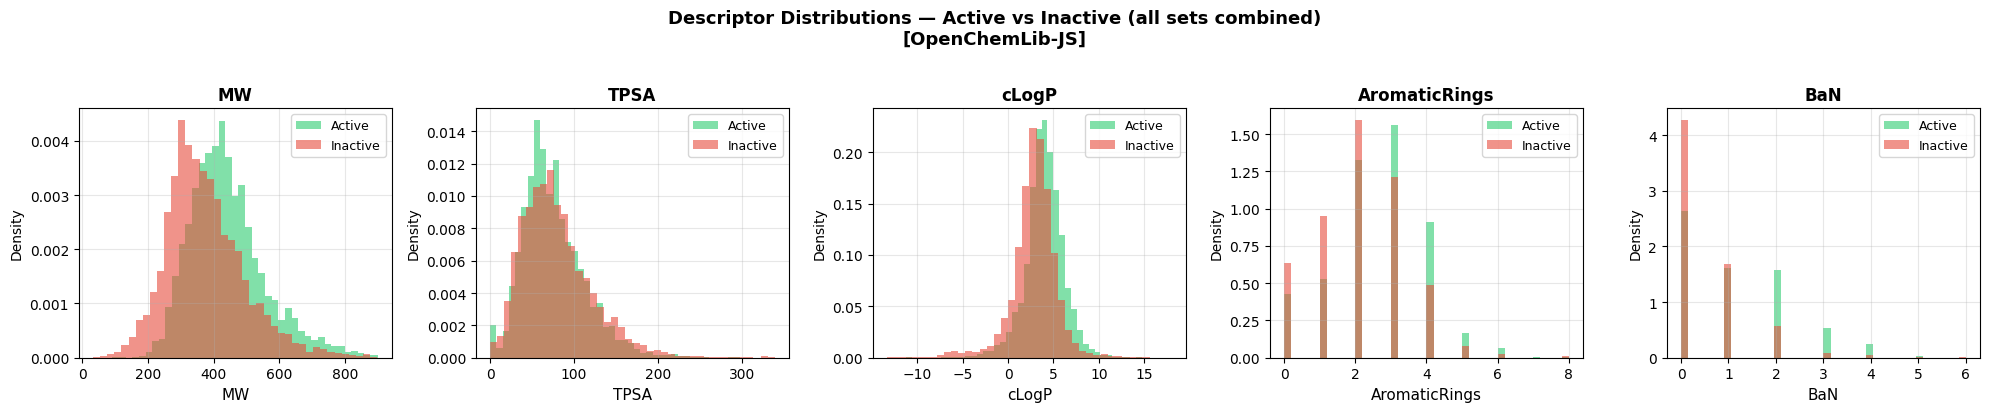


Descriptor summary (mean) by class:
               MW       TPSA  cLogP  AromaticRings   BaN
label                                                   
0      373.829987  80.080002   2.82           2.07  0.50
1      442.839996  75.750000   4.00           2.56  1.14


In [11]:
def extract_desc_unscaled(df, smiles_col, label_col):
    """Extract unscaled descriptors via OpenChemLib-JS for plotting."""
    # Get valid SMILES
    valid_smiles, valid_labels = [], []
    label_mapping = {'Active': 1, 'Inactive': 0}
    for _, row in df.iterrows():
        mol = Chem.MolFromSmiles(str(row[smiles_col]))
        if mol is None:
            continue
        valid_smiles.append(str(row[smiles_col]))
        valid_labels.append(label_mapping.get(row[label_col], -1))

    print(f"[OCL] Calculating descriptors for {len(valid_smiles)} molecules...")
    desc_map = run_ocl_descriptors(valid_smiles)

    rows = []
    for smi, lbl in zip(valid_smiles, valid_labels):
        if smi not in desc_map:
            continue
        d = desc_map[smi]
        rows.append({'MW': d[0], 'TPSA': d[1], 'cLogP': d[2],
                     'AromaticRings': d[3], 'BaN': d[4], 'label': lbl})
    return pd.DataFrame(rows)


all_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
desc_df = extract_desc_unscaled(all_df, SMILES_COL, LABEL_COL)

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
colors = {1: '#2ecc71', 0: '#e74c3c'}
for ax, desc in zip(axes, DESC_NAMES):
    for cls in [1, 0]:
        ax.hist(desc_df[desc_df['label'] == cls][desc], bins=40,
                alpha=0.6, color=colors[cls],
                label='Active' if cls == 1 else 'Inactive', density=True)
    ax.set_xlabel(desc, fontsize=11)
    ax.set_ylabel('Density', fontsize=10)
    ax.set_title(desc, fontsize=12, fontweight='bold')
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('Descriptor Distributions — Active vs Inactive (all sets combined)\n[OpenChemLib-JS]',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('descriptor_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nDescriptor summary (mean) by class:")
print(desc_df.groupby('label')[DESC_NAMES].mean().round(2).to_string())


## 5. Evaluation Metrics

In [12]:
def compute_metrics(y_true, y_pred, y_prob=None):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    m = {
        'Accuracy':    accuracy_score(y_true, y_pred),
        'Precision':   precision_score(y_true, y_pred, zero_division=0),
        'Sensitivity': recall_score(y_true, y_pred, zero_division=0),
        'Specificity': tn / (tn + fp) if (tn + fp) > 0 else 0.0,
        'F1':          f1_score(y_true, y_pred, zero_division=0),
        'Kappa':       cohen_kappa_score(y_true, y_pred),
        'MCC':         matthews_corrcoef(y_true, y_pred),
    }
    if y_prob is not None:
        m['AUROC'] = roc_auc_score(y_true, y_prob)
    m.update({'TP': int(tp), 'TN': int(tn), 'FP': int(fp), 'FN': int(fn)})
    return m


def print_metrics(m, title="Metrics"):
    print(f"\n{'='*52}\n  {title}\n{'='*52}")
    for k, v in m.items():
        print(f"  {k:15s}: {v:.4f}" if isinstance(v, float) else f"  {k:15s}: {v}")

print("Metrics functions ready")

Metrics functions ready


## 6. Hyperparameter Optimisation

Grid search over **nT** (n_trees) and **Td** (max_depth) evaluated on the internal validation set.  
Paper optimal for RF-1: **nT=150, Td=50**.

In [13]:
QUICK_RUN = True   # Set False for full paper grid (50-400 trees, depth 10-50)

N_TREES_GRID    = [50, 100, 150, 200, 300]      if QUICK_RUN else list(range(50, 450, 50))
TREE_DEPTH_GRID = [20, 30, 40, 50]              if QUICK_RUN else [10, 20, 30, 40, 50]

print(f"Grid: {len(N_TREES_GRID)} nT values x {len(TREE_DEPTH_GRID)} Td values = {len(N_TREES_GRID)*len(TREE_DEPTH_GRID)} combinations")

hp_rows = []
with tqdm(total=len(N_TREES_GRID)*len(TREE_DEPTH_GRID), desc="Grid search") as pbar:
    for nT in N_TREES_GRID:
        for Td in TREE_DEPTH_GRID:
            rf = RandomForestClassifier(n_estimators=nT, max_depth=Td,
                                        n_jobs=-1, random_state=42, oob_score=True)
            rf.fit(X_train, y_train)
            yp = rf.predict(X_val)
            ypr = rf.predict_proba(X_val)[:, 1]
            hp_rows.append({'n_trees': nT, 'tree_depth': Td,
                            'val_accuracy': accuracy_score(y_val, yp),
                            'val_auroc':    roc_auc_score(y_val, ypr),
                            'oob_accuracy': rf.oob_score_})
            pbar.update(1)

hp_results = pd.DataFrame(hp_rows)
best_row   = hp_results.loc[hp_results['val_accuracy'].idxmax()]
best_nT    = int(best_row.n_trees)
best_Td    = int(best_row.tree_depth)

print(f"\nBest: nT={best_nT}, Td={best_Td}")
print(f"  Val Accuracy : {best_row.val_accuracy:.4f}")
print(f"  Val AUROC    : {best_row.val_auroc:.4f}")
print(f"  OOB Accuracy : {best_row.oob_accuracy:.4f}")

Grid: 5 nT values x 4 Td values = 20 combinations


Grid search:   0%|          | 0/20 [00:00<?, ?it/s]


Best: nT=150, Td=30
  Val Accuracy : 0.9147
  Val AUROC    : 0.9713
  OOB Accuracy : 0.9135


### 6.1 Hyperparameter Heatmap

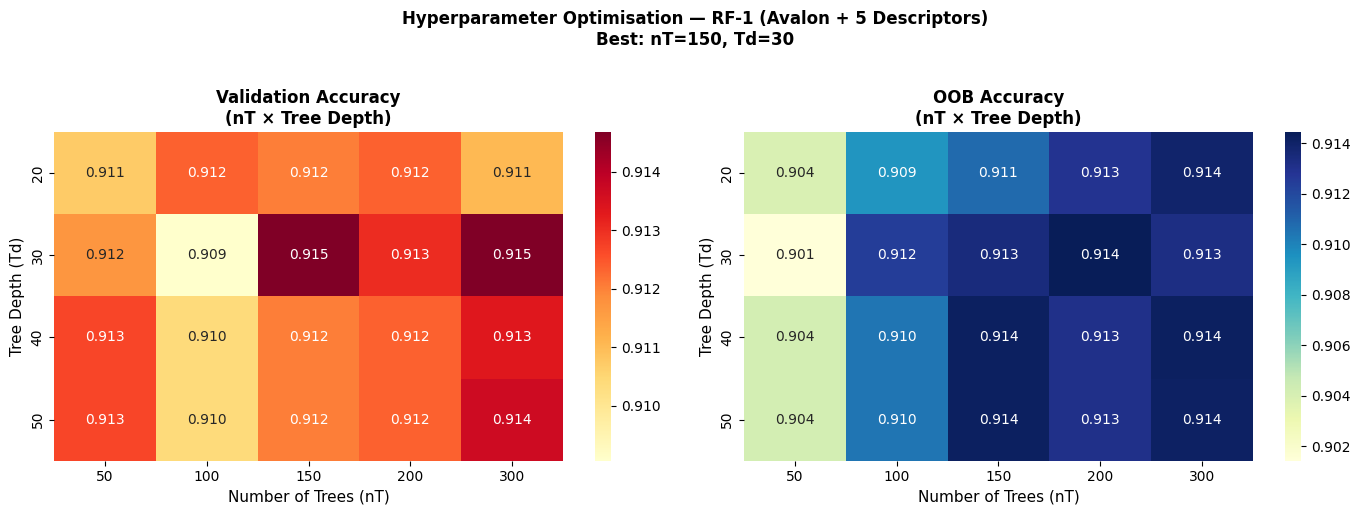

In [14]:
pivot_acc = hp_results.pivot(index='tree_depth', columns='n_trees', values='val_accuracy')
pivot_oob = hp_results.pivot(index='tree_depth', columns='n_trees', values='oob_accuracy')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, piv, title, cmap in zip(axes,
                                  [pivot_acc, pivot_oob],
                                  ['Validation Accuracy', 'OOB Accuracy'],
                                  ['YlOrRd', 'YlGnBu']):
    sns.heatmap(piv, annot=True, fmt='.3f', cmap=cmap, ax=ax)
    ax.set_title(f'{title}\n(nT × Tree Depth)', fontweight='bold', fontsize=12)
    ax.set_xlabel('Number of Trees (nT)', fontsize=11)
    ax.set_ylabel('Tree Depth (Td)', fontsize=11)

plt.suptitle(f'Hyperparameter Optimisation — RF-1 (Avalon + 5 Descriptors)\nBest: nT={best_nT}, Td={best_Td}',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('hp_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

## 7. Train Final RF-1 Model & Evaluate on External Test Set

In [15]:
print(f"Training final model on dev set ({len(y_dev):,} samples): nT={best_nT}, Td={best_Td}")

rf_model = RandomForestClassifier(
    n_estimators=best_nT, max_depth=best_Td,
    n_jobs=-1, random_state=42, oob_score=True
)
rf_model.fit(X_dev, y_dev)
print(f"  OOB accuracy (dev set): {rf_model.oob_score_:.4f}")

y_pred_test = rf_model.predict(X_test)
y_prob_test = rf_model.predict_proba(X_test)[:, 1]
test_metrics = compute_metrics(y_test, y_pred_test, y_prob_test)

print_metrics(test_metrics,
    "External Test Set — RF-1 (Avalon 1024 + MW + TPSA + cLogP + AromaticRings + BaN)")
print("\nPaper target (Avalon only): Acc=0.917 | Prec=0.935 | Sens=0.884 | AUROC=0.973")

Training final model on dev set (12,094 samples): nT=150, Td=30
  OOB accuracy (dev set): 0.9190

  External Test Set — RF-1 (Avalon 1024 + MW + TPSA + cLogP + AromaticRings + BaN)
  Accuracy       : 0.9315
  Precision      : 0.9512
  Sensitivity    : 0.8991
  Specificity    : 0.9598
  F1             : 0.9244
  Kappa          : 0.8620
  MCC            : 0.8631
  AUROC          : 0.9792
  TP             : 1266
  TN             : 1551
  FP             : 65
  FN             : 142

Paper target (Avalon only): Acc=0.917 | Prec=0.935 | Sens=0.884 | AUROC=0.973


### 7.1 ROC Curve (Fig. 3 replication)

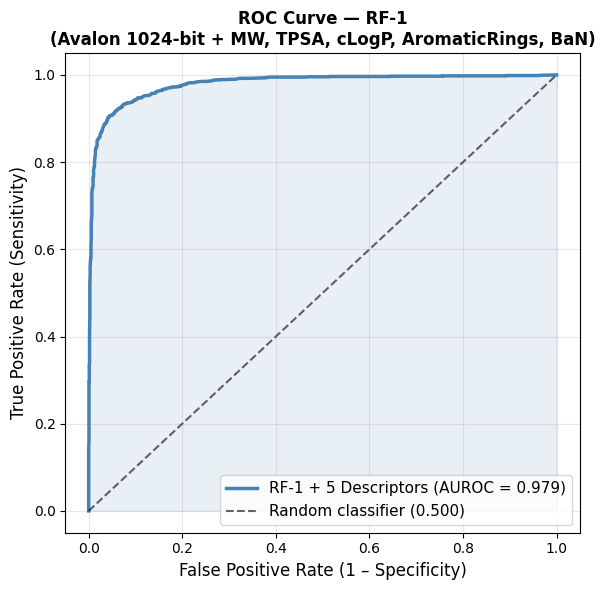

In [16]:
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
auroc = test_metrics['AUROC']

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot(fpr, tpr, color='steelblue', lw=2.5,
        label=f'RF-1 + 5 Descriptors (AUROC = {auroc:.3f})')
ax.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.6, label='Random classifier (0.500)')
ax.fill_between(fpr, tpr, alpha=0.12, color='steelblue')
ax.set_xlabel('False Positive Rate (1 – Specificity)', fontsize=12)
ax.set_ylabel('True Positive Rate (Sensitivity)', fontsize=12)
ax.set_title('ROC Curve — RF-1\n(Avalon 1024-bit + MW, TPSA, cLogP, AromaticRings, BaN)',
             fontsize=12, fontweight='bold')
ax.legend(loc='lower right', fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve.png', dpi=150, bbox_inches='tight')
plt.show()

### 7.2 Confusion Matrix

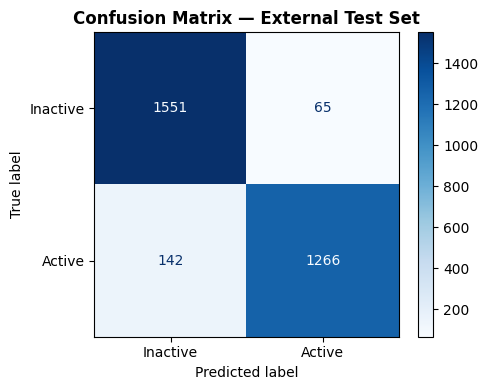

In [17]:
cm = confusion_matrix(y_test, y_pred_test)
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(cm, display_labels=['Inactive', 'Active']).plot(
    ax=ax, colorbar=True, cmap='Blues')
ax.set_title('Confusion Matrix — External Test Set', fontweight='bold')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Model Validation

### 8.1 OOB Error Rate vs. Number of Trees (Fig. 4 replication)

nT sweep:   0%|          | 0/15 [00:00<?, ?it/s]

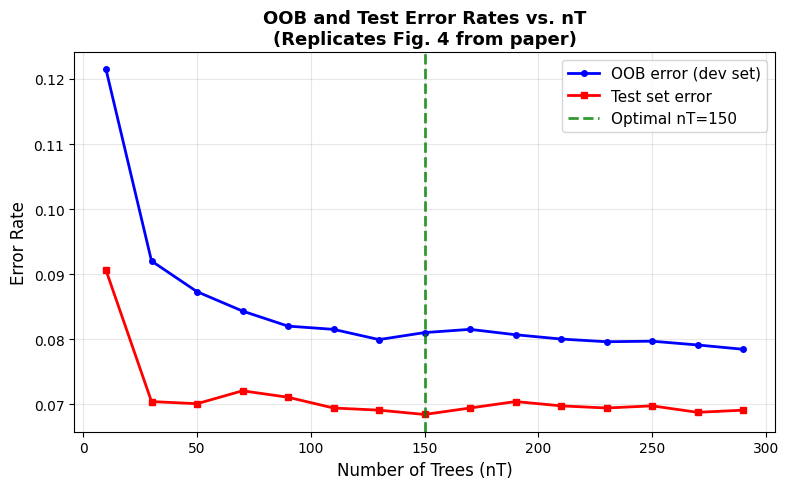

In [18]:
sweep = list(range(10, 310, 20))
oob_errs, test_errs = [], []

for nT in tqdm(sweep, desc="nT sweep"):
    rf_tmp = RandomForestClassifier(n_estimators=nT, max_depth=best_Td,
                                    oob_score=True, n_jobs=-1, random_state=42)
    rf_tmp.fit(X_dev, y_dev)
    oob_errs.append(1 - rf_tmp.oob_score_)
    test_errs.append(1 - accuracy_score(y_test, rf_tmp.predict(X_test)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(sweep, oob_errs,  'b-o', ms=4, lw=2, label='OOB error (dev set)')
ax.plot(sweep, test_errs, 'r-s', ms=4, lw=2, label='Test set error')
ax.axvline(best_nT, color='green', ls='--', lw=2, alpha=0.8, label=f'Optimal nT={best_nT}')
ax.set_xlabel('Number of Trees (nT)', fontsize=12)
ax.set_ylabel('Error Rate', fontsize=12)
ax.set_title('OOB and Test Error Rates vs. nT\n(Replicates Fig. 4 from paper)',
             fontsize=13, fontweight='bold')
ax.legend(fontsize=11)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('oob_vs_ntrees.png', dpi=150, bbox_inches='tight')
plt.show()

### 8.2 10-fold CV × 10 Repeats (Table 2 replication)

In [19]:
cv_records = []
key_metrics = ['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']

print("Running 10-fold CV x 10 repeats...")
for repeat in tqdm(range(10), desc="CV repeats"):
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=repeat)
    fold_m = []
    for tr_idx, v_idx in skf.split(X_dev, y_dev):
        rf_cv = RandomForestClassifier(n_estimators=best_nT, max_depth=best_Td,
                                       n_jobs=-1, random_state=42)
        rf_cv.fit(X_dev[tr_idx], y_dev[tr_idx])
        m = compute_metrics(y_dev[v_idx],
                            rf_cv.predict(X_dev[v_idx]),
                            rf_cv.predict_proba(X_dev[v_idx])[:, 1])
        fold_m.append(m)
    avg = {k: np.mean([fm[k] for fm in fold_m]) for k in key_metrics}
    avg['repeat'] = repeat + 1
    cv_records.append(avg)

cv_df      = pd.DataFrame(cv_records)
cv_summary = cv_df[key_metrics].agg(['mean','std'])
print("\n10-fold CV Results (Table 2 equivalent):")
print(cv_summary.round(4).to_string())

Running 10-fold CV x 10 repeats...


CV repeats:   0%|          | 0/10 [00:00<?, ?it/s]


10-fold CV Results (Table 2 equivalent):
      Accuracy  Precision  Sensitivity  Specificity      F1   Kappa     MCC   AUROC
mean    0.9190     0.9413       0.8811       0.9521  0.9101  0.8366  0.8382  0.9727
std     0.0009     0.0013       0.0010       0.0011  0.0010  0.0018  0.0018  0.0004


### 8.3 Y-Scrambling (Table 3 replication)

Y-scrambling:   0%|          | 0/100 [00:00<?, ?it/s]


Y-Scrambling (Table 3 equivalent):
  Real model accuracy   : 0.9315
  Scrambled mean ± std  : 0.5044 ± 0.0079
  Expected (random)     : ~0.500


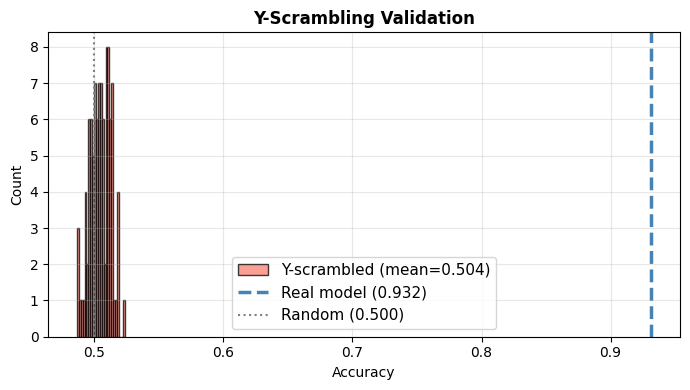

In [20]:
rng = np.random.RandomState(42)
scrambled_accs = [accuracy_score(rng.permutation(y_test), y_pred_test)
                  for _ in tqdm(range(100), desc="Y-scrambling")]

print(f"\nY-Scrambling (Table 3 equivalent):")
print(f"  Real model accuracy   : {test_metrics['Accuracy']:.4f}")
print(f"  Scrambled mean ± std  : {np.mean(scrambled_accs):.4f} ± {np.std(scrambled_accs):.4f}")
print(f"  Expected (random)     : ~0.500")

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(scrambled_accs, bins=25, color='salmon', alpha=0.75, edgecolor='k',
        label=f'Y-scrambled (mean={np.mean(scrambled_accs):.3f})')
ax.axvline(test_metrics['Accuracy'], color='steelblue', lw=2.5, ls='--',
           label=f"Real model ({test_metrics['Accuracy']:.3f})")
ax.axvline(0.5, color='gray', lw=1.5, ls=':', label='Random (0.500)')
ax.set_xlabel('Accuracy'); ax.set_ylabel('Count')
ax.set_title('Y-Scrambling Validation', fontweight='bold')
ax.legend(fontsize=11); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('y_scrambling.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Applicability Domain (APD)
Euclidean NN distances in the Avalon 1024-bit space (matching the paper).

Computing APD (Euclidean NN distances in Avalon space)...
  APD threshold (P99): 14.866
  Outside APD: 8/3024 (0.3%)
  (Paper reported ~0.4% outside APD)


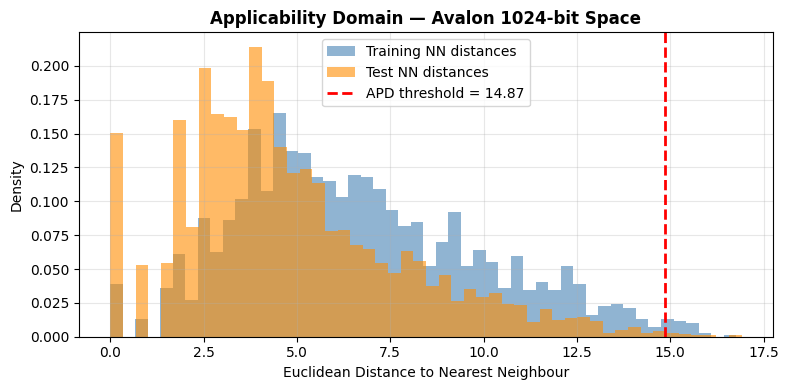

In [21]:
# Sample training set for efficiency
n_samp = min(2000, len(X_train_fp))
samp_idx = np.random.choice(len(X_train_fp), n_samp, replace=False)
X_samp = X_train_fp[samp_idx]

print("Computing APD (Euclidean NN distances in Avalon space)...")
tr_d = cdist(X_samp, X_samp, metric='euclidean')
np.fill_diagonal(tr_d, np.inf)
train_nn_d = tr_d.min(axis=1)

APD_PERCENTILE = 99
apd_threshold  = np.percentile(train_nn_d, APD_PERCENTILE)

test_nn_d    = cdist(X_test_fp, X_train_fp, metric='euclidean').min(axis=1)
outside_apd  = test_nn_d > apd_threshold

print(f"  APD threshold (P{APD_PERCENTILE}): {apd_threshold:.3f}")
print(f"  Outside APD: {outside_apd.sum()}/{len(X_test)} ({100*outside_apd.mean():.1f}%)")
print(f"  (Paper reported ~0.4% outside APD)")

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(train_nn_d, bins=50, alpha=0.6, color='steelblue', density=True, label='Training NN distances')
ax.hist(test_nn_d,  bins=50, alpha=0.6, color='darkorange', density=True, label='Test NN distances')
ax.axvline(apd_threshold, color='red', lw=2, ls='--',
           label=f'APD threshold = {apd_threshold:.2f}')
ax.set_xlabel('Euclidean Distance to Nearest Neighbour')
ax.set_ylabel('Density')
ax.set_title('Applicability Domain — Avalon 1024-bit Space', fontweight='bold')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('applicability_domain.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Feature Importance — Avalon Bits vs 5 Descriptors

Feature importance — 5 descriptors:
  MW             : 0.020695  |||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
  TPSA           : 0.009466  |||||||||||||||||||||||||||||||||||||||||||||||
  cLogP          : 0.015184  |||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
  AromaticRings  : 0.006083  ||||||||||||||||||||||||||||||
  BaN            : 0.012586  ||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||

  Avalon bits (sum)  : 0.935986
  Descriptors (sum)  : 0.064014


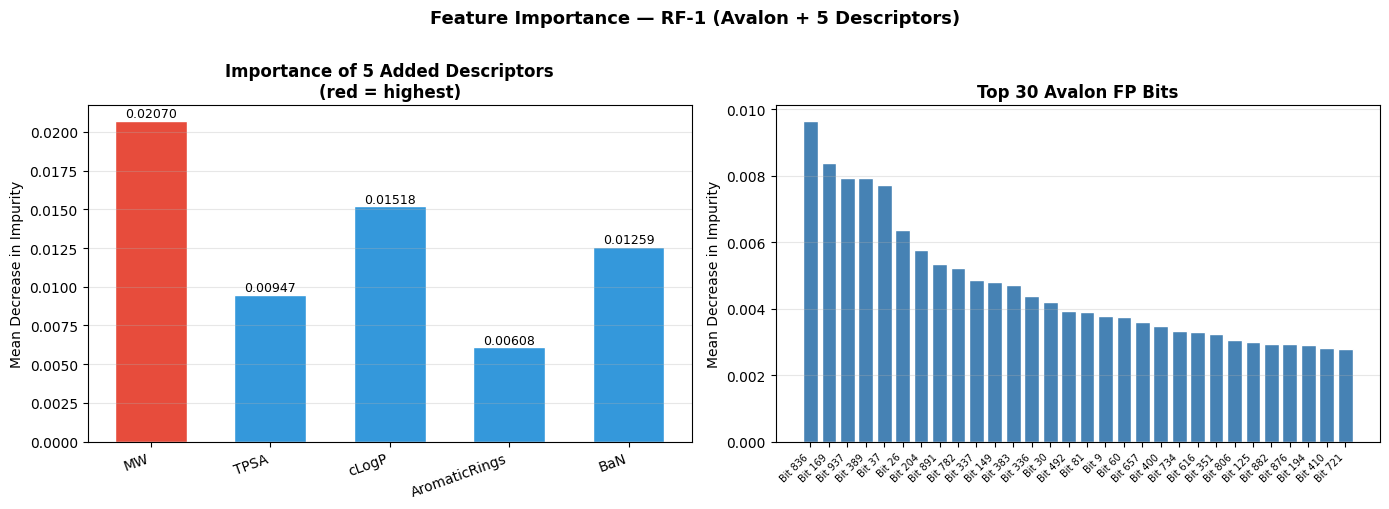

In [22]:
importances  = rf_model.feature_importances_
avalon_imp   = importances[:AVALON_NBITS]
desc_imp     = importances[AVALON_NBITS:]

print("Feature importance — 5 descriptors:")
for name, val in zip(DESC_NAMES, desc_imp):
    print(f"  {name:15s}: {val:.6f}  {'|' * int(val*5000)}")
print(f"\n  Avalon bits (sum)  : {avalon_imp.sum():.6f}")
print(f"  Descriptors (sum)  : {desc_imp.sum():.6f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: 5 descriptor importances
ax = axes[0]
bar_colors = ['#e74c3c' if v == desc_imp.max() else '#3498db' for v in desc_imp]
bars = ax.bar(DESC_NAMES, desc_imp, color=bar_colors, edgecolor='white', width=0.6)
for b, v in zip(bars, desc_imp):
    ax.text(b.get_x() + b.get_width()/2, v + 0.00005,
            f'{v:.5f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Mean Decrease in Impurity')
ax.set_title('Importance of 5 Added Descriptors\n(red = highest)', fontweight='bold')
ax.grid(axis='y', alpha=0.3)
plt.setp(ax.get_xticklabels(), rotation=20, ha='right')

# Right: top 30 Avalon bits
ax2 = axes[1]
top30 = np.argsort(avalon_imp)[::-1][:30]
ax2.bar(range(30), avalon_imp[top30], color='steelblue', edgecolor='white')
ax2.set_xticks(range(30))
ax2.set_xticklabels([f'Bit {top30[i]}' for i in range(30)],
                    rotation=45, ha='right', fontsize=7)
ax2.set_ylabel('Mean Decrease in Impurity')
ax2.set_title('Top 30 Avalon FP Bits', fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

plt.suptitle('Feature Importance — RF-1 (Avalon + 5 Descriptors)',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Virtual Screening — Predict New Compounds

Supply BaN values from DataWarrior via the `ban_values` list (same order as SMILES).  
If `ban_values=None`, the RDKit approximation is used automatically.

In [23]:
def screen_compounds(smiles_list, names=None):
    """
    Screen new SMILES strings using the trained RF-1 model.
    Descriptors are calculated via OpenChemLib-JS.

    Parameters
    ----------
    smiles_list : list of SMILES
    names       : list of compound names (optional)
    """
    # Filter to valid SMILES first
    valid_entries = []
    results = []
    for i, smi in enumerate(smiles_list):
        name = names[i] if names else f"Cpd_{i+1}"
        mol = Chem.MolFromSmiles(str(smi))
        if mol is None:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': 'Invalid SMILES', 'P(Active)': None,
                            'Within_APD': None, **{d: None for d in DESC_NAMES}})
        else:
            valid_entries.append((i, name, smi))

    if not valid_entries:
        return pd.DataFrame(results)

    # Batch OCL descriptor calculation
    valid_smiles = [e[2] for e in valid_entries]
    print(f"[OCL] Calculating descriptors for {len(valid_smiles)} molecules...")
    desc_map = run_ocl_descriptors(valid_smiles)

    for (i, name, smi) in valid_entries:
        if smi not in desc_map:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': 'OCL error', 'P(Active)': None,
                            'Within_APD': None, **{d: None for d in DESC_NAMES}})
            continue
        try:
            mol     = Chem.MolFromSmiles(smi)
            desc    = desc_map[smi]                            # [MW, TPSA, cLogP, Arom, BaN]
            fp      = calc_avalon_fp(mol, n_bits=AVALON_NBITS)
            desc_sc = scaler.transform(desc.reshape(1, -1))[0]
            feat    = np.hstack([fp, desc_sc]).reshape(1, -1)

            pred    = rf_model.predict(feat)[0]
            prob    = float(rf_model.predict_proba(feat)[0][1])
            nn_dist = cdist(fp.reshape(1, -1), X_train_fp, metric='euclidean').min()
            in_apd  = bool(nn_dist <= apd_threshold)

            results.append({
                'Name':          name,
                'SMILES':        smi,
                'Prediction':    'Active' if pred == 1 else 'Inactive',
                'P(Active)':     round(prob, 4),
                'Within_APD':    in_apd,
                'MW':            round(float(desc[0]), 2),
                'TPSA':          round(float(desc[1]), 2),
                'cLogP':         round(float(desc[2]), 2),
                'AromaticRings': int(desc[3]),
                'BaN':           int(desc[4]),
            })
        except Exception as e:
            results.append({'Name': name, 'SMILES': smi,
                            'Prediction': f'Error: {e}', 'P(Active)': None,
                            'Within_APD': None, **{d: None for d in DESC_NAMES}})

    return pd.DataFrame(results)


# Example screen — replace with your own compounds
example = [
    ("Chloroquine",        "CCN(CC)CCCC(C)Nc1ccnc2cc(Cl)ccc12"),
    ("Artemisinin",        "[C@@H]1([C@H]2CC[C@H](OO[C@@]3([C@H]([C@@H]2O3)C)C)C)C(=O)O[C@H]1"),
    ("Mefloquine",         "OC(c1cc(C(F)(F)F)nc2c(C(F)(F)F)cccc12)C1CCCCN1"),
    ("Quinine",            "COc1ccc2nccc(C(O)C3CC4CCN3CC4C=C)c2c1"),
    ("CEP-37440 (Cpd 1)",  "FC(F)(F)c1ccc(Nc2nc(N3CC[C@@H](NCc4ccc(Cl)cc4)C3)c(Cl)cn2)cc1"),
    ("AZD-1480 (Cpd 2)",   "CC(Cc1c[nH]c2ccccc12)Nc1nc(N)c2c(n1)CCC2"),
    ("Aspirin (inactive)", "CC(=O)Oc1ccccc1C(=O)O"),
    ("Caffeine (inactive)","Cn1cnc2c1c(=O)n(C)c(=O)n2C"),
]
names_ex, smiles_ex = zip(*example)

screen_df = screen_compounds(list(smiles_ex), list(names_ex))
print("Virtual Screening Results:")
print(screen_df.to_string(index=False))


[OCL] Calculating descriptors for 8 molecules...
Virtual Screening Results:
               Name                                                            SMILES Prediction  P(Active)  Within_APD     MW  TPSA  cLogP  AromaticRings  BaN
        Chloroquine                                 CCN(CC)CCCC(C)Nc1ccnc2cc(Cl)ccc12     Active     0.9732        True 319.88 28.16   4.01              2    2
        Artemisinin [C@@H]1([C@H]2CC[C@H](OO[C@@]3([C@H]([C@@H]2O3)C)C)C)C(=O)O[C@H]1   Inactive     0.3533        True 255.29 53.99   1.42              0    0
         Mefloquine                    OC(c1cc(C(F)(F)F)nc2c(C(F)(F)F)cccc12)C1CCCCN1     Active     0.9533        True 378.32 45.15   3.51              2    1
            Quinine                             COc1ccc2nccc(C(O)C3CC4CCN3CC4C=C)c2c1     Active     0.9867        True 324.42 45.59   2.61              2    1
  CEP-37440 (Cpd 1)     FC(F)(F)c1ccc(Nc2nc(N3CC[C@@H](NCc4ccc(Cl)cc4)C3)c(Cl)cn2)cc1     Active     0.6633        True 482.

## 12. Summary Dashboard

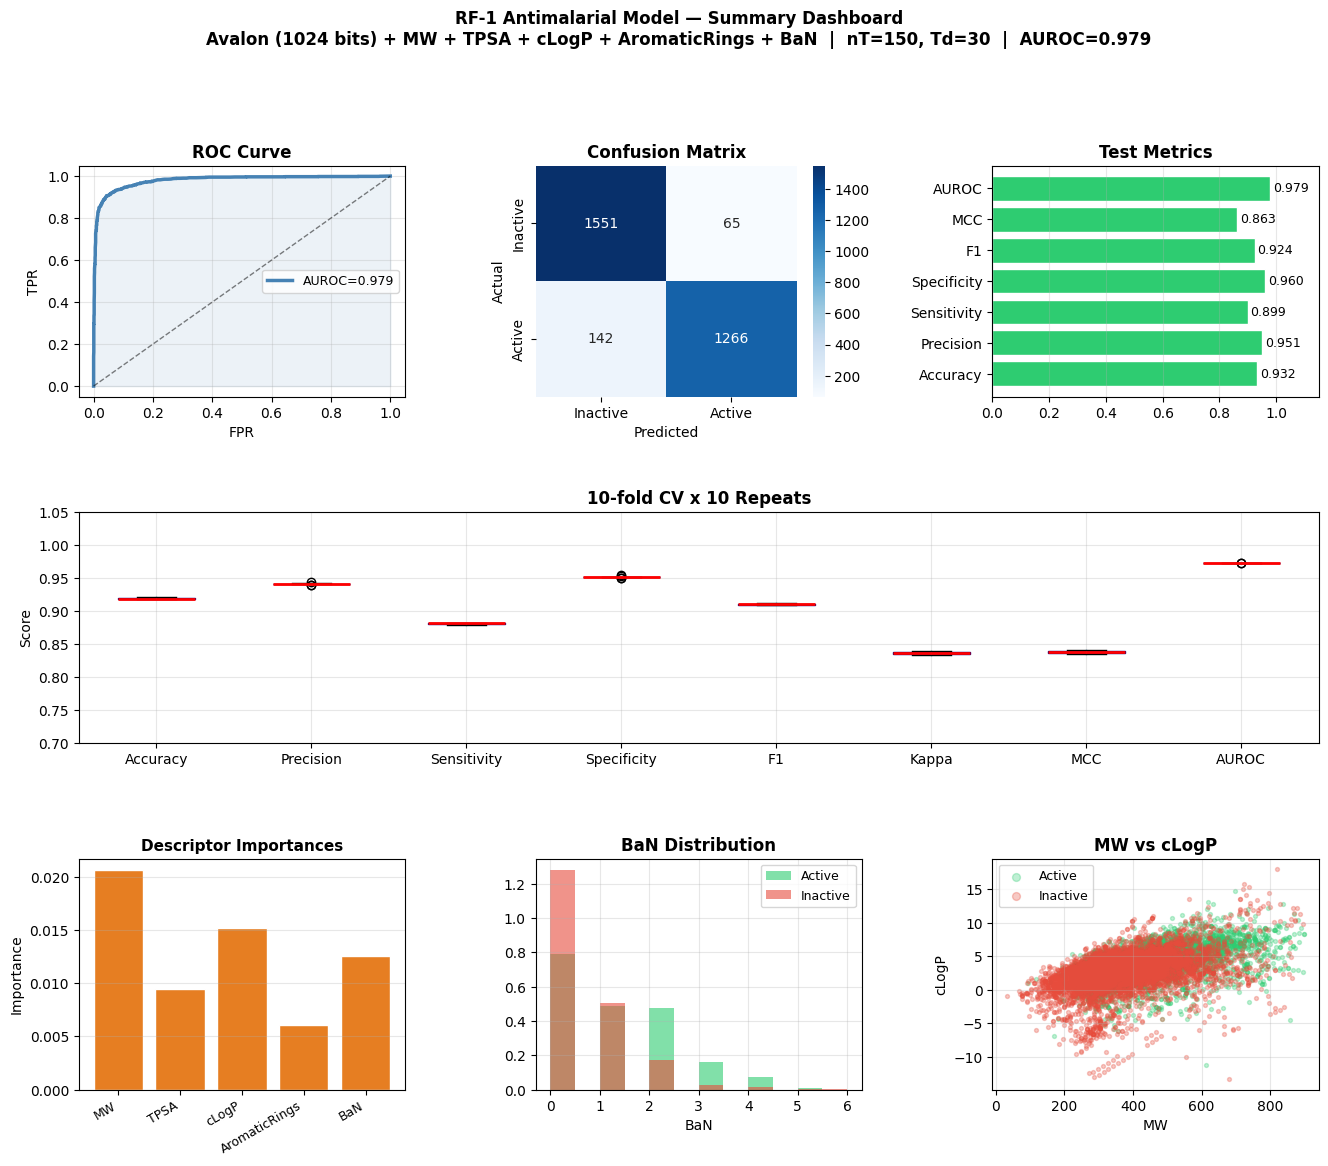

Dashboard saved.


In [24]:
fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.5, wspace=0.4)

# ROC
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(fpr, tpr, 'steelblue', lw=2.5, label=f'AUROC={auroc:.3f}')
ax1.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
ax1.fill_between(fpr,tpr,alpha=0.1,color='steelblue')
ax1.set_xlabel('FPR'); ax1.set_ylabel('TPR')
ax1.set_title('ROC Curve',fontweight='bold')
ax1.legend(fontsize=9); ax1.grid(alpha=0.3)

# Confusion matrix
ax2 = fig.add_subplot(gs[0, 1])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax2,
            xticklabels=['Inactive','Active'], yticklabels=['Inactive','Active'])
ax2.set_title('Confusion Matrix',fontweight='bold')
ax2.set_xlabel('Predicted'); ax2.set_ylabel('Actual')

# Metrics bar
ax3 = fig.add_subplot(gs[0, 2])
mk = ['Accuracy','Precision','Sensitivity','Specificity','F1','MCC','AUROC']
mv = [test_metrics[k] for k in mk]
bars3 = ax3.barh(mk, mv, color='#2ecc71', edgecolor='white')
ax3.set_xlim([0,1.15])
for b,v in zip(bars3,mv):
    ax3.text(v+0.01,b.get_y()+b.get_height()/2,f'{v:.3f}',va='center',fontsize=9)
ax3.set_title('Test Metrics',fontweight='bold'); ax3.grid(axis='x',alpha=0.3)

# CV boxplots
ax4 = fig.add_subplot(gs[1, :])
cv_df[['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']].boxplot(
    ax=ax4, patch_artist=True,
    boxprops=dict(facecolor='lightblue',color='navy'),
    medianprops=dict(color='red',lw=2))
ax4.set_title('10-fold CV x 10 Repeats',fontweight='bold',fontsize=12)
ax4.set_ylabel('Score'); ax4.grid(alpha=0.3); ax4.set_ylim([0.7,1.05])

# Descriptor importance
ax5 = fig.add_subplot(gs[2, 0])
ax5.bar(DESC_NAMES, desc_imp, color='#e67e22', edgecolor='white')
ax5.set_title('Descriptor Importances',fontweight='bold',fontsize=11)
ax5.set_ylabel('Importance'); ax5.grid(axis='y',alpha=0.3)
plt.setp(ax5.get_xticklabels(),rotation=30,ha='right',fontsize=9)

# BaN distribution
ax6 = fig.add_subplot(gs[2, 1])
for cls, col, lbl in [(1,'#2ecc71','Active'),(0,'#e74c3c','Inactive')]:
    ax6.hist(desc_df[desc_df['label']==cls]['BaN'],bins=12,
             alpha=0.6,color=col,label=lbl,density=True)
ax6.set_xlabel('BaN'); ax6.set_title('BaN Distribution',fontweight='bold')
ax6.legend(fontsize=9); ax6.grid(alpha=0.3)

# cLogP vs MW
ax7 = fig.add_subplot(gs[2, 2])
for cls, col, lbl in [(1,'#2ecc71','Active'),(0,'#e74c3c','Inactive')]:
    s = desc_df[desc_df['label']==cls]
    ax7.scatter(s['MW'],s['cLogP'],c=col,alpha=0.3,s=8,label=lbl)
ax7.set_xlabel('MW'); ax7.set_ylabel('cLogP')
ax7.set_title('MW vs cLogP',fontweight='bold')
ax7.legend(fontsize=9,markerscale=2); ax7.grid(alpha=0.3)

fig.suptitle(
    f'RF-1 Antimalarial Model — Summary Dashboard\n'
    f'Avalon ({AVALON_NBITS} bits) + MW + TPSA + cLogP + AromaticRings + BaN  |  '
    f'nT={best_nT}, Td={best_Td}  |  AUROC={auroc:.3f}',
    fontsize=12, fontweight='bold', y=1.01)
plt.savefig('summary_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard saved.")

In [25]:
# ── Save model to Google Drive ──────────────────────────
model_bundle = {
    'model':         rf_model,
    'scaler':        scaler,
    'fingerprint':   'avalon',
    'n_bits':        AVALON_NBITS,
    'descriptors':   DESC_NAMES,
    'n_features':    X_train.shape[1],
    'n_trees':       best_nT,
    'tree_depth':    best_Td,
    'apd_threshold': apd_threshold,
    'ban_source':    'OpenChemLib-JS (pKa-based port of AtomFunctionAnalyzer)',
    'test_metrics':  test_metrics,
}

# Save model
model_path = PROJECT_DIR + 'rf1_antimalarial_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_bundle, f)
print(f"Model saved to Drive: {model_path}")

# Save active SMILES list (needed by Notebook 5)
active_smiles = list(
    train_df[train_df[LABEL_COL] == 'Active'][SMILES_COL].values
)
actives_path = PROJECT_DIR + 'clean_actives.pkl'
with open(actives_path, 'wb') as f:
    pickle.dump(active_smiles, f)
print(f"Active SMILES saved: {len(active_smiles)} molecules → {actives_path}")

# Save all SMILES list (needed for novelty scoring)
all_smiles = list(
    pd.concat([train_df, val_df, test_df])[SMILES_COL].values
)
all_path = PROJECT_DIR + 'clean_all.pkl'
with open(all_path, 'wb') as f:
    pickle.dump(all_smiles, f)
print(f"All SMILES saved: {len(all_smiles)} molecules → {all_path}")

Model saved to Drive: /content/drive/MyDrive/antimalarial_project/rf1_antimalarial_model.pkl
Active SMILES saved: 4223 molecules → /content/drive/MyDrive/antimalarial_project/clean_actives.pkl
All SMILES saved: 15118 molecules → /content/drive/MyDrive/antimalarial_project/clean_all.pkl


## 13. Save Model and Scaler

In [26]:
model_bundle = {
    'model':            rf_model,
    'scaler':           scaler,        # StandardScaler fitted on training set
    'fingerprint':      'avalon',
    'n_bits':           AVALON_NBITS,
    'descriptors':      DESC_NAMES,    # ['MW','TPSA','cLogP','AromaticRings','BaN']
    'n_features':       X_train.shape[1],
    'n_trees':          best_nT,
    'tree_depth':       best_Td,
    'apd_threshold':    apd_threshold,
    'ban_source':       'OpenChemLib-JS (pKa-based port of AtomFunctionAnalyzer)',
    'test_metrics':     test_metrics,
}

with open('rf1_antimalarial_model.pkl', 'wb') as f:
    pickle.dump(model_bundle, f)

print("Model saved to rf1_antimalarial_model.pkl")
print(f"\nFeatures   : Avalon {AVALON_NBITS} bits + {', '.join(DESC_NAMES)} = {X_train.shape[1]} total")
# NEW
print(f"BaN source : OpenChemLib-JS (pKa-based port of AtomFunctionAnalyzer)")
print(f"nT / Td    : {best_nT} / {best_Td}")
for k in ['Accuracy','Precision','Sensitivity','Specificity','F1','Kappa','MCC','AUROC']:
    print(f"{k:15s}: {test_metrics[k]:.4f}")

Model saved to rf1_antimalarial_model.pkl

Features   : Avalon 1024 bits + MW, TPSA, cLogP, AromaticRings, BaN = 1029 total
BaN source : OpenChemLib-JS (pKa-based port of AtomFunctionAnalyzer)
nT / Td    : 150 / 30
Accuracy       : 0.9315
Precision      : 0.9512
Sensitivity    : 0.8991
Specificity    : 0.9598
F1             : 0.9244
Kappa          : 0.8620
MCC            : 0.8631
AUROC          : 0.9792


In [27]:
# ── Save model to Google Drive ──────────────────────────
model_bundle = {
    'model':         rf_model,
    'scaler':        scaler,
    'fingerprint':   'avalon',
    'n_bits':        AVALON_NBITS,
    'descriptors':   DESC_NAMES,
    'n_features':    X_train.shape[1],
    'n_trees':       best_nT,
    'tree_depth':    best_Td,
    'apd_threshold': apd_threshold,
    'ban_source':    'OpenChemLib-JS (pKa-based port of AtomFunctionAnalyzer)',
    'test_metrics':  test_metrics,
}

# Save model
model_path = PROJECT_DIR + 'rf1_antimalarial_model.pkl'
with open(model_path, 'wb') as f:
    pickle.dump(model_bundle, f)
print(f"Model saved to Drive: {model_path}")

# Save active SMILES list (needed by Notebook 5)
active_smiles = list(
    train_df[train_df[LABEL_COL] == 'Active'][SMILES_COL].values
)
actives_path = PROJECT_DIR + 'clean_actives.pkl'
with open(actives_path, 'wb') as f:
    pickle.dump(active_smiles, f)
print(f"Active SMILES saved: {len(active_smiles)} molecules → {actives_path}")

# Save all SMILES list (needed for novelty scoring)
all_smiles = list(
    pd.concat([train_df, val_df, test_df])[SMILES_COL].values
)
all_path = PROJECT_DIR + 'clean_all.pkl'
with open(all_path, 'wb') as f:
    pickle.dump(all_smiles, f)
print(f"All SMILES saved: {len(all_smiles)} molecules → {all_path}")

Model saved to Drive: /content/drive/MyDrive/antimalarial_project/rf1_antimalarial_model.pkl
Active SMILES saved: 4223 molecules → /content/drive/MyDrive/antimalarial_project/clean_actives.pkl
All SMILES saved: 15118 molecules → /content/drive/MyDrive/antimalarial_project/clean_all.pkl


---
## Important Notes

### Descriptor Backend: OpenChemLib-JS
All 5 physicochemical descriptors (MW, TPSA, cLogP, AromaticRings, BaN) are now calculated
using the `openchemlib` npm package via a Node.js subprocess.  
This replaces the previous RDKit-based descriptor functions.

- **BaN (Basic Nitrogen):** Exact port of `AtomFunctionAnalyzer.isBasicNitrogen()` from
  OpenChemLib Java source (Actelion Pharmaceuticals Ltd., BSD-3 licence).
  Counts N atoms with pKa > 7: aliphatic amines, imines, aromatic N enabled by ortho/para
  donors (e.g. 4-aminopyridine), imidazole-type N. Excludes anilines, unactivated pyridine,
  amides, sulfonamides, pyrrole-type N, nitriles.
- **TPSA, cLogP, MW** use `MoleculeProperties` and `MolecularFormula` from OpenChemLib.
- **AromaticRings** uses `Molecule.getAromaticRingCount()`.

### Avalon Fingerprints
The Avalon FP is still computed via RDKit (`rdkit.Avalon.pyAvalonTools`). If unavailable,
the notebook falls back to the RDKit topological fingerprint.

### Descriptor Scaling
The `StandardScaler` is **fitted only on the training set** and then applied to val/test/screening
compounds — this prevents data leakage. The fitted scaler is saved in the model bundle.

### Feature Vector Layout
```
Index  0 – 1023 : Avalon fingerprint bits (binary)
Index 1024      : MW            (standardised, OpenChemLib)
Index 1025      : TPSA          (standardised, OpenChemLib)
Index 1026      : cLogP         (standardised, OpenChemLib)
Index 1027      : AromaticRings (standardised, OpenChemLib)
Index 1028      : BaN           (standardised, OpenChemLib pKa-based)
```

---
*Paper: Kore M et al. BMC Chemistry 19, 28 (2025). https://doi.org/10.1186/s13065-025-01395-4*


In [ ]:
# ============================================================
#  SECTION 14 — Classify Unlabelled CSV/TSV File
# ============================================================
# Edit the two settings below, then run this cell.
# ------------------------------------------------------------

# Path to your input file (CSV or TSV). Change to your actual filename.
# Examples:
#   INPUT_FILE = "my_compounds.csv"
#   INPUT_FILE = "/content/drive/MyDrive/antimalarial_project/screen.tsv"
INPUT_FILE = "output (1).csv"   # <-- EDIT THIS

# Name of the column that holds SMILES strings in your file
SMILES_COL_NEW = "SMILES_CODE"          # <-- EDIT THIS if your column has a different name

# (Optional) Path to save the results CSV. Set to None to skip saving.
OUTPUT_FILE = "classified_results.csv"

# ============================================================
#  Do NOT edit below this line
# ============================================================

import os
import pandas as pd
import numpy as np
from scipy.spatial.distance import cdist


def classify_from_file(filepath, smiles_col, rf_model, scaler, apd_threshold, X_train_fp, n_bits=1024):

    # 1. Load file
    ext = os.path.splitext(filepath)[1].lower()
    sep = "\t" if ext == ".tsv" else ","

    if not os.path.isfile(filepath):
        raise FileNotFoundError(
            f"File not found: '{filepath}'\n"
            "  → If you're in Colab, upload the file first via the Files panel "
            "(folder icon on the left sidebar), or mount your Drive and provide "
            "the full Drive path."
        )

    df_in = pd.read_csv(filepath, sep=sep)
    print(f"Loaded '{filepath}': {len(df_in):,} rows, {len(df_in.columns)} columns")
    print(f"Columns: {list(df_in.columns)}")

    if smiles_col not in df_in.columns:
        raise ValueError(
            f"Column '{smiles_col}' not found in file.\n"
            f"Available columns: {list(df_in.columns)}\n"
            f"Set SMILES_COL_NEW to the correct column name."
        )

    # 2. Validate SMILES
    from rdkit import Chem, DataStructs

    valid_rows, invalid_idx = [], []
    for idx, row in df_in.iterrows():
        smi = str(row[smiles_col])
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            valid_rows.append((idx, smi))
        else:
            invalid_idx.append(idx)

    print(f"\nValid SMILES  : {len(valid_rows):,}")
    print(f"Invalid SMILES: {len(invalid_idx):,} (will be marked 'Invalid SMILES' in output)")

    # 3. Batch-calculate OCL descriptors
    valid_smiles_list = [smi for (_, smi) in valid_rows]
    print(f"\n[OCL] Calculating descriptors for {len(valid_smiles_list):,} molecules...")
    desc_map = run_ocl_descriptors(valid_smiles_list)

    # 4. Build feature matrix and predict
    result_records = {}

    # Initialize all rows with defaults
    for idx in df_in.index:
        result_records[idx] = {
            "Prediction": "Invalid SMILES",
            "P(Active)": None,
            "Within_APD": None,
            "MW": None, "TPSA": None, "cLogP": None,
            "AromaticRings": None, "BaN": None,
        }

    n_ocl_fail = 0
    for (orig_idx, smi) in valid_rows:
        if smi not in desc_map:
            result_records[orig_idx]["Prediction"] = "Descriptor error"
            n_ocl_fail += 1
            continue

        try:
            mol     = Chem.MolFromSmiles(smi)
            desc    = desc_map[smi]
            fp      = calc_avalon_fp(mol, n_bits=n_bits)
            desc_sc = scaler.transform(desc.reshape(1, -1))[0]
            feat    = np.hstack([fp, desc_sc]).reshape(1, -1)

            pred   = rf_model.predict(feat)[0]
            prob   = float(rf_model.predict_proba(feat)[0][1])
            nn_d   = cdist(fp.reshape(1, -1), X_train_fp, metric="euclidean").min()
            in_apd = bool(nn_d <= apd_threshold)

            result_records[orig_idx] = {
                "Prediction":    "Active" if pred == 1 else "Inactive",
                "P(Active)":     round(prob, 4),
                "Within_APD":    in_apd,
                "MW":            round(float(desc[0]), 2),
                "TPSA":          round(float(desc[1]), 2),
                "cLogP":         round(float(desc[2]), 2),
                "AromaticRings": int(desc[3]),
                "BaN":           int(desc[4]),
            }
        except Exception as exc:
            result_records[orig_idx]["Prediction"] = f"Error: {exc}"

    if n_ocl_fail:
        print(f"[OCL] Descriptor calculation failed for {n_ocl_fail} molecule(s).")

    # 5. Assemble output DataFrame
    results_df = pd.DataFrame.from_dict(result_records, orient="index")
    results_df.index = df_in.index
    df_out = pd.concat([df_in, results_df], axis=1)

    # 6. Summary
    pred_col   = df_out["Prediction"]
    n_active   = (pred_col == "Active").sum()
    n_inactive = (pred_col == "Inactive").sum()
    n_in_apd   = df_out["Within_APD"].sum()

    print("\n" + "=" * 50)
    print("  CLASSIFICATION RESULTS")
    print("=" * 50)
    print(f"  Total compounds     : {len(df_in):,}")
    print(f"  Valid SMILES        : {len(valid_rows):,}")
    print(f"  Active (predicted)  : {n_active:,}  ({100*n_active/max(len(valid_rows),1):.1f}%)")
    print(f"  Inactive (predicted): {n_inactive:,}  ({100*n_inactive/max(len(valid_rows),1):.1f}%)")
    print(f"  Within APD          : {n_in_apd:,}  ({100*n_in_apd/max(len(valid_rows),1):.1f}%)")
    print("=" * 50)

    return df_out


# Run
results_df = classify_from_file(
    filepath      = INPUT_FILE,
    smiles_col    = SMILES_COL_NEW,
    rf_model      = rf_model,
    scaler        = scaler,
    apd_threshold = apd_threshold,
    X_train_fp    = X_train_fp,
    n_bits        = AVALON_NBITS,
)

# Preview
display_cols = [SMILES_COL_NEW, "Prediction", "P(Active)", "Within_APD",
                "MW", "TPSA", "cLogP", "AromaticRings", "BaN"]
available_display = [c for c in display_cols if c in results_df.columns]

print("\nFirst 20 rows of results:")
try:
    from IPython.display import display
    display(results_df[available_display].head(20))
except ImportError:
    print(results_df[available_display].head(20).to_string(index=False))

# Save
if OUTPUT_FILE:
    results_df.to_csv(OUTPUT_FILE, index=False)
    print(f"\nResults saved to: '{OUTPUT_FILE}'")

    # Also copy to Drive if mounted in Colab
    try:
        drive_out = PROJECT_DIR + os.path.basename(OUTPUT_FILE)
        results_df.to_csv(drive_out, index=False)
        print(f"Also saved to Drive: '{drive_out}'")
    except Exception:
        pass

Loaded 'output (1).csv': 363,169 rows, 32 columns
Columns: ['Structure [idcode]', 'Structure No', 'Catalog ID', 'MW', 'cLogP 2', 'Polar Surface Area', 'Aromatic Rings', 'Basic Nitrogens', 'Largest Fragment of Structure [idcode]', 'ACMS_Score', 'Result', 'Failed BaN', 'Failed_Category', 'Failed cLogP', 'Failed AR', 'Failed TPSA', 'Dataset Name', 'Molecule Name', 'Catalog_NO', 'CAS', 'SMILES', 'Target', 'Pathway', 'ID', 'URL', 'Data Added', 'Molweight', 'Nasty Functions', 'PAINS Patterns', 'Structure 2 [idcode]', 'Smiles 2', 'SMILES_CODE']


Streaming output truncated to the last 5000 lines.
[11:54:11] Conflicting single bond directions around double bond at index 15.
[11:54:11]   BondStereo set to STEREONONE and single bond directions set to NONE.
[11:54:11] Conflicting single bond directions around double bond at index 16.
[11:54:11]   BondStereo set to STEREONONE and single bond directions set to NONE.
[11:54:11] Conflicting single bond directions around double bond at index 17.
[11:54:11]   BondStereo set to STEREONONE and single bond directions set to NONE.
[11:54:11] Conflicting single bond directions around double bond at index 5.
[11:54:11]   BondStereo set to STEREONONE and single bond directions set to NONE.
[11:54:11] Conflicting single bond directions around double bond at index 13.
[11:54:11]   BondStereo set to STEREONONE and single bond directions set to NONE.
[11:54:11] Conflicting single bond directions around double bond at index 7.
[11:54:11]   BondStereo set to STEREONONE and single bond directions set 


Valid SMILES  : 363,156
Invalid SMILES: 13 (will be marked 'Invalid SMILES' in output)

[OCL] Calculating descriptors for 363,156 molecules...


Streaming output truncated to the last 5000 lines.
[13:29:25] Conflicting single bond directions around double bond at index 4.
[13:29:25]   BondStereo set to STEREONONE and single bond directions set to NONE.
[13:29:25] Conflicting single bond directions around double bond at index 10.
[13:29:25]   BondStereo set to STEREONONE and single bond directions set to NONE.
[13:29:26] Conflicting single bond directions around double bond at index 4.
[13:29:26]   BondStereo set to STEREONONE and single bond directions set to NONE.
[13:29:27] Conflicting single bond directions around double bond at index 4.
[13:29:27]   BondStereo set to STEREONONE and single bond directions set to NONE.
[13:29:28] Conflicting single bond directions around double bond at index 7.
[13:29:28]   BondStereo set to STEREONONE and single bond directions set to NONE.
[13:29:28] Conflicting single bond directions around double bond at index 10.
[13:29:28]   BondStereo set to STEREONONE and single bond directions set to

In [ ]:
# ============================================================
#  Extract Top 10 Active and Top 10 Inactive by P(Active)
# ============================================================

import pandas as pd

# Load the classified results
classified_df = pd.read_csv(OUTPUT_FILE)

# Separate Active and Inactive predictions
active_df   = classified_df[classified_df["Prediction"] == "Active"].copy()
inactive_df = classified_df[classified_df["Prediction"] == "Inactive"].copy()

# Top 10 Active — highest P(Active)
top10_active = (active_df
                .sort_values("P(Active)", ascending=False)
                .head(10)
                .reset_index(drop=True))

# Top 10 Inactive — lowest P(Active) (most confidently inactive)
top10_inactive = (inactive_df
                  .sort_values("P(Active)", ascending=True)
                  .head(10)
                  .reset_index(drop=True))

# Add a rank column for clarity
top10_active["Rank"]   = range(1, 11)
top10_inactive["Rank"] = range(1, 11)

# Combine into one file with a label column
top10_active["Group"]   = "Top10_Active"
top10_inactive["Group"] = "Top10_Inactive"

top20_df = pd.concat([top10_active, top10_inactive], ignore_index=True)

# Save
TOP_OUTPUT_FILE = "top10_active_inactive.csv"
top20_df.to_csv(TOP_OUTPUT_FILE, index=False)

# Also save to Drive if mounted
try:
    drive_out = PROJECT_DIR + TOP_OUTPUT_FILE
    top20_df.to_csv(drive_out, index=False)
    print(f"Also saved to Drive: '{drive_out}'")
except Exception:
    pass

# Preview
print(f"\nTop 10 Active molecules (highest P(Active)):")
from IPython.display import display
display(top10_active[["Rank", "Structure", "P(Active)", "Within_APD",
                       "molecularWeight", "cLogP", "basicNitrogenCount",
                       "aromaticRingCount"]].to_string(index=False))

print(f"\nTop 10 Inactive molecules (lowest P(Active)):")
display(top10_inactive[["Rank", "Structure", "P(Active)", "Within_APD",
                         "molecularWeight", "cLogP", "basicNitrogenCount",
                         "aromaticRingCount"]].to_string(index=False))

print(f"\nSaved {len(top20_df)} molecules to '{TOP_OUTPUT_FILE}'")
print(f"  Top 10 Active   — P(Active) range: {top10_active['P(Active)'].min():.4f} – {top10_active['P(Active)'].max():.4f}")
print(f"  Top 10 Inactive — P(Active) range: {top10_inactive['P(Active)'].min():.4f} – {top10_inactive['P(Active)'].max():.4f}")

In [ ]:
def estimate_cost(n_iterations=100, n_strategies=3,
                  n_generate_per_iter=15, model="claude-3-5-haiku-20241022"):

    pricing = {
        "claude-3-haiku-20240307":     {"input": 0.25,  "output": 1.25},
        "claude-3-5-haiku-20241022":   {"input": 0.84,  "output": 4.20},
        "claude-haiku-4-5":            {"input": 1.00,  "output": 5.00},
        "claude-3-5-sonnet-20241022":  {"input": 3.00,  "output": 15.00},
    }

    price = pricing.get(model, pricing["claude-3-5-haiku-20241022"])
    tokens_per_call = 150 + 400 + (n_generate_per_iter * 25)
    calls = {"zero_shot": 1, "domain_knowledge": 1, "reflection": 2}

    print(f"\nCost Estimate — {model}")
    print("="*45)
    total = 0
    for strategy, n_calls in calls.items():
        total_tokens = n_iterations * n_calls * tokens_per_call
        cost = (total_tokens * 0.6 / 1e6 * price["input"] +
                total_tokens * 0.4 / 1e6 * price["output"])
        total += cost
        print(f"  {strategy:20s}: ~${cost:.2f}")
    print("="*45)
    print(f"  TOTAL: ~${total:.2f}")
    print(f"\n  Compare: GPT-4o-mini would cost ~$1-2 for the same run.")
    print(f"  Claude Haiku is similarly cheap — both are fine for pilot runs.")

estimate_cost(model="claude-3-5-haiku-20241022")

In [ ]:
import pickle

with open('rf1_antimalarial_model.pkl', 'rb') as f:
    rf_model = pickle.load(f)

print("RF model loaded and ready.")

In [ ]:
estimate_cost(n_iterations=100, n_generate_per_iter=15, model="claude-3-5-haiku-20241022")

In [ ]:
# -------------------------------------------------------
# Every time you restart Colab, run this cell to reload
# the saved model — no need to retrain every session
# -------------------------------------------------------

import pickle

with open('rf1_antimalarial_model.pkl', 'rb') as f:
    rf_model = pickle.load(f)

print("RF model loaded and ready.")

# -------------------------------------------------------
# NOW YOU CAN RUN THE EXPERIMENT
# Uncomment one at a time, run to completion, then next
# -------------------------------------------------------

# First: check estimated cost
estimate_cost(n_iterations=100, n_generate_per_iter=15, model="gpt-4o-mini")

# Then run experiments one at a time:

# pool_zs, scores_zs = run_full_experiment(
#     strategy="zero_shot",
#     seed_actives=valid_smiles,       # the active SMILES from your dataset
#     training_smiles=valid_smiles,    # all SMILES for novelty scoring
#     rf_model=rf_model,
#     n_iterations=100,
# )

# pool_dk, scores_dk = run_full_experiment(
#     strategy="domain_knowledge",
#     seed_actives=valid_smiles,
#     training_smiles=valid_smiles,
#     rf_model=rf_model,
#     n_iterations=100,
# )

# pool_ref, scores_ref = run_full_experiment(
#     strategy="reflection",
#     seed_actives=valid_smiles,
#     training_smiles=valid_smiles,
#     rf_model=rf_model,
#     n_iterations=100,
# )

In [ ]:
utils_code = r'''
# ============================================================
# utils.py — shared functions for the antimalarial LLM pipeline
# All notebooks import from this file
# ============================================================

import re, time, json, random, pickle
import numpy as np
import pandas as pd
from datetime import datetime
from rdkit import Chem, DataStructs
import subprocess as _subprocess, json as _json
from rdkit.Chem.AllChem import GetMorganFingerprintAsBitVect

try:
    from rdkit.Avalon import pyAvalonTools
    AVALON_AVAILABLE = True
except ImportError:
    AVALON_AVAILABLE = False


# ============================================================
# SECTION 1 — RF helpers (from Notebook 1)
# ============================================================

_OCL_LIB = '/tmp/ocl/node_modules/openchemlib/dist/openchemlib.js'

_OCL_DESC_JS = r"""
import OCL from '""" + _OCL_LIB + r"""';
const { Molecule, MoleculeProperties } = OCL;
function getFakeOxoCount(mol,atom){let n=0;for(let i=0;i<mol.getConnAtoms(atom);i++){const no=mol.getAtomicNo(mol.getConnAtom(atom,i));if(mol.getConnBondOrder(atom,i)===2&&(no===7||no===8||no===16))n++;}return n;}
function isStabilized(mol,atom,twice){let found=false;for(let i=0;i<mol.getConnAtoms(atom);i++){const bond=mol.getConnBond(atom,i);if(!mol.isAromaticBond(bond)&&mol.getConnBondOrder(atom,i)===1){const conn=mol.getConnAtom(atom,i);if(!mol.isAromaticAtom(conn)&&((mol.getAtomicNo(conn)===6&&getFakeOxoCount(mol,conn)===1)||(mol.getAtomicNo(conn)===16&&getFakeOxoCount(mol,conn)===2))){if(found||!twice)return true;found=true;}}}return false;}
function isVinylogFakeOxo(mol,atom){for(let i=0;i<mol.getConnAtoms(atom);i++){if(mol.getConnBondOrder(atom,i)!==1){const conn=mol.getConnAtom(atom,i);for(let j=0;j<mol.getConnAtoms(conn);j++)if(mol.getConnBondOrder(conn,j)===1&&getFakeOxoCount(mol,mol.getConnAtom(conn,j))!==0)return true;}}return false;}
function isBasicNitrogen(mol,atom){if(mol.getAtomicNo(atom)!==7)return false;if(mol.getAtomCharge(atom)!==0)return false;if(mol.getConnAtoms(atom)+mol.getAtomPi(atom)>3)return false;if(mol.isAromaticAtom(atom)){if(mol.getAtomPi(atom)!==1)return false;if(mol.getAtomRingCount(atom,7)!==1)return false;const rc=mol.getRingSet();for(let r=0;r<rc.getSize();r++){if(!rc.isAtomMember(r,atom))continue;const sz=rc.getRingSize(r);if(sz!==5&&sz!==6){break;}const ring=rc.getRingAtoms(r);const R=Array.from({length:sz},(_,i)=>ring[i]);let ni=R.indexOf(atom);let opi,mi;if(sz===5){opi=[R[ni-1<0?ni+4:ni-1],R[ni-4<0?ni+1:ni-4]];mi=[R[ni-2<0?ni+3:ni-2],R[ni-3<0?ni+2:ni-3]];}else{opi=[R[ni-1<0?ni+5:ni-1],R[ni-3<0?ni+3:ni-3],R[ni-5<0?ni+1:ni-5]];mi=[R[ni-2<0?ni+4:ni-2],R[ni-4<0?ni+2:ni-4]];}let ec=0;for(let i=0;i<R.length;i++)if(atom!==R[i]&&mol.getAtomicNo(R[i])===7&&mol.getAtomPi(R[i])===1)ec--;for(let i=0;i<opi.length;i++){let exoAtom=-1,exoBond=-1;for(let j=0;j<mol.getConnAtoms(opi[i]);j++){if(!mol.isAromaticBond(mol.getConnBond(opi[i],j))){exoAtom=mol.getConnAtom(opi[i],j);exoBond=mol.getConnBond(opi[i],j);break;}}if(exoAtom!==-1){if(mol.getAtomicNo(exoAtom)===7&&mol.getAtomPi(exoAtom)===0&&(mol.getConnAtoms(exoAtom)+mol.getAtomPi(exoAtom)<=3)&&!isStabilized(mol,exoAtom,false)){ec++;continue;}if(mol.getAtomicNo(exoAtom)===8&&mol.getConnAtoms(exoAtom)===1){ec+=2;continue;}if(mol.isAromaticBond(exoBond)){for(let s=0;s<rc.getSize();s++){if(rc.isAromatic(s)&&rc.isAtomMember(s,exoAtom)){const ra=rc.getRingAtoms(s);for(let j=0;j<rc.getRingSize(s);j++)if(mol.getAtomicNo(ra[j])===7&&mol.getAtomPi(ra[j])===1){ec--;break;}break;}}}}}for(let i=0;i<mi.length;i++){let exoAtom=-1;for(let j=0;j<mol.getConnAtoms(mi[i]);j++)if(!mol.isAromaticBond(mol.getConnBond(mi[i],j)))exoAtom=mol.getConnAtom(mi[i],j);if(mol.getAtomicNo(mi[i])===6){if(exoAtom!==-1&&getFakeOxoCount(mol,exoAtom)!==0)ec--;}else if(mol.getAtomicNo(mi[i])===7){if(mol.getAtomPi(mi[i])===0&&(exoAtom===-1||(!mol.isAromaticAtom(exoAtom)&&getFakeOxoCount(mol,exoAtom)===0)))ec++;}}return ec>0;}return false;}if(mol.getAtomPi(atom)>1)return false;if(mol.getAtomPi(atom)===1){let imineC=-1,sc=0;for(let i=0;i<mol.getConnAtoms(atom);i++){const conn=mol.getConnAtom(atom,i);if(mol.getConnBondOrder(atom,i)===2){if(mol.getAtomicNo(conn)!==6)return false;imineC=conn;continue;}if(mol.getAtomicNo(conn)===8)return false;if(mol.getAtomicNo(conn)===7){sc--;if(isStabilized(mol,conn,false))sc--;continue;}if(mol.isAromaticAtom(conn))sc--;}if(imineC===-1)return false;let arNC=0;for(let i=0;i<mol.getConnAtoms(imineC);i++){if(mol.getConnBondOrder(imineC,i)===1){const conn=mol.getConnAtom(imineC,i);if(getFakeOxoCount(mol,conn)!==0)return false;if(mol.isAromaticAtom(conn))arNC++;if(mol.getAtomicNo(conn)===7&&!isStabilized(mol,conn,true))sc++;if(mol.getAtomicNo(conn)===8||mol.getAtomicNo(conn)===16)sc--;}}if(arNC===2)sc--;return sc>=0;}for(let i=0;i<mol.getConnAtoms(atom);i++){const conn=mol.getConnAtom(atom,i);if(mol.isAromaticAtom(conn))return false;if(mol.getAtomicNo(conn)!==6)return false;if(getFakeOxoCount(mol,conn)!==0)return false;if(mol.getAtomPi(conn)!==0&&isVinylogFakeOxo(mol,conn))return false;}return true;}
function countBasicNitrogens(mol){let n=0;for(let i=0;i<mol.getAllAtoms();i++)if(isBasicNitrogen(mol,i))n++;return n;}
const smilesList=JSON.parse(process.argv[2]);
const results=[];
for(const smi of smilesList){try{const mol=Molecule.fromSmiles(smi);mol.ensureHelperArrays(255);const props=new MoleculeProperties(mol);const formula=mol.getMolecularFormula();results.push({smi,mw:parseFloat(formula.relativeWeight.toFixed(3)),tpsa:parseFloat(props.polarSurfaceArea.toFixed(3)),clogp:parseFloat(props.logP.toFixed(3)),arom:mol.getAromaticRingCount(),ban:countBasicNitrogens(mol),hbd:props.donorCount,hba:props.acceptorCount});}catch(e){results.push({smi,error:e.message});}}
process.stdout.write(JSON.stringify(results));
"""

def _run_ocl(smiles_list):
    """Batch-calculate OCL descriptors; returns dict smi -> dict of properties."""
    if not smiles_list:
        return {}
    with open('/tmp/_ocl_utils.mjs', 'w') as _f:
        _f.write(_OCL_DESC_JS)
    _r = _subprocess.run(
        ['node', '/tmp/_ocl_utils.mjs', _json.dumps(smiles_list)],
        capture_output=True, text=True, timeout=300
    )
    if _r.returncode != 0:
        return {}
    return {row['smi']: row for row in _json.loads(_r.stdout) if 'error' not in row}


# calc_ban_rdkit removed — BaN now computed via OpenChemLib-JS (_run_ocl)


def calc_avalon_fp(mol, n_bits=1024):
    if AVALON_AVAILABLE:
        fp = pyAvalonTools.GetAvalonFP(mol, nBits=n_bits)
    else:
        fp = Chem.RDKFingerprint(mol, fpSize=n_bits)
    arr = np.zeros(fp.GetNumBits(), dtype=np.float32)
    DataStructs.ConvertToNumpyArray(fp, arr)
    return arr


def calc_five_descriptors(smi_or_mol):
    """Single-molecule OCL descriptor calc. Accepts SMILES string or RDKit mol."""
    if isinstance(smi_or_mol, str):
        smi = smi_or_mol
    else:
        smi = Chem.MolToSmiles(smi_or_mol)
    row = _run_ocl([smi]).get(smi)
    if row is None:
        return np.zeros(5, dtype=np.float32)
    return np.array([row['mw'], row['tpsa'], row['clogp'], row['arom'], row['ban']],
                    dtype=np.float32)


# ============================================================
# SECTION 2 — LLM generation (from Notebook 2/3)
# ============================================================

def call_llm(client, system_prompt, user_prompt,
             model="anthropic/claude-3-5-haiku", temperature=0.9):
    response = client.chat.completions.create(
        model=model,
        temperature=temperature,
        messages=[
            {"role": "system", "content": system_prompt},
            {"role": "user",   "content": user_prompt}
        ]
    )
    return response.choices[0].message.content


def extract_valid_smiles(llm_response_text):
    smiles_pattern = r'[A-Za-z][A-Za-z0-9@+\-\[\]\(\)=#$\/\\%\.]+'
    candidates = re.findall(smiles_pattern, llm_response_text)
    common_words = {'The', 'This', 'These', 'Here', 'Note', 'Each',
                    'For', 'With', 'From', 'SMILES', 'InChI'}
    valid_smiles = []
    seen = set()
    for candidate in candidates:
        if len(candidate) < 3:
            continue
        if candidate in common_words:
            continue
        has_smiles_chars = bool(re.search(r'[0-9@+\-\[\]\(\)=#$\/\\%\.]', candidate))
        if not has_smiles_chars:
            continue
        mol = Chem.MolFromSmiles(candidate)
        if mol is not None:
            canonical = Chem.MolToSmiles(mol)
            if canonical not in seen:
                seen.add(canonical)
                valid_smiles.append(canonical)
    return valid_smiles


def generate_zero_shot(client, known_active_smiles, n_generate=10):
    examples = random.sample(known_active_smiles, min(10, len(known_active_smiles)))
    examples_text = "\n".join(examples)
    system_prompt = """You are a computational medicinal chemist.
Your task is to generate novel drug candidate molecules in SMILES format.
Always output SMILES strings one per line, with no numbering, no names,
no explanations — just the raw SMILES strings."""
    user_prompt = f"""Here are {len(examples)} known antimalarial drug molecules (SMILES format):

{examples_text}

Generate {n_generate} NEW and NOVEL antimalarial drug candidate molecules in SMILES format.
Output only SMILES strings, one per line. No explanations."""
    print(f"[Zero-Shot] Calling LLM...")
    response_text = call_llm(client, system_prompt, user_prompt)
    valid = extract_valid_smiles(response_text)
    print(f"[Zero-Shot] Generated {len(valid)} valid SMILES")
    return valid, response_text


def generate_with_domain_knowledge(client, known_active_smiles, n_generate=10):
    examples = random.sample(known_active_smiles, min(10, len(known_active_smiles)))
    examples_text = "\n".join(examples)
    system_prompt = """You are an expert medicinal chemist with 20 years of experience
in antiparasitic drug discovery, specifically designing small molecules active
against asexual blood stages (ABS) of Plasmodium falciparum.

You are familiar with the RF-1 random forest model (Avalon fingerprints, AUROC=0.973)
trained on ~15,000 ChEMBL molecules with confirmed IC50/EC50 values against P. falciparum.
You understand the antimalarial chemical space: higher MW, higher clogP, more basic
nitrogens, more aromatic rings, and lower TPSA than typical oral drugs.

Output SMILES strings one per line, no numbering, no names, no explanations."""
    user_prompt = f"""Here are {len(examples)} confirmed antimalarial compounds with IC50 < 200 nM
against P. falciparum ABS (SYBR Green I assay), curated from ChEMBL:
{examples_text}

Generate {n_generate} novel antimalarial drug candidates. Follow ALL constraints:

ASSAY CONTEXT (Kore et al. 2025):
- Target: Plasmodium falciparum asexual blood stages (ABS)
- Active threshold: IC50 < 200 nM in the RF-1 model
- Avoid: PAINS, reactive groups, aggregators

VALIDATED SCAFFOLD FAMILIES:
- 4-Aminoquinolines: chloroquine/amodiaquine-type; halogen at C7, basic sidechain
- 8-Aminoquinolines: primaquine-type; methoxy substituents, terminal primary amine
- 2,4-Diaminoquinazolines: histone methyltransferase inhibitor series
- 2,4-Diamino-5-chloropyrimidines: chemotype of CEP-37440 and AZD-1480

ANTIMALARIAL PROPERTY SPACE (NOT standard Lipinski):
- MW: 200-900 Da (antimalarials are heavier than typical oral drugs)
- clogP: 1.0-6.5 (more lipophilic for parasite uptake)
- Basic nitrogen count (BaN): >= 1 (essential for food vacuole accumulation)
- Aromatic rings: >= 2 (polycyclic character)
- TPSA: <= 90 Angstrom squared (lower than oral drugs)

MECHANISTIC GUIDANCE:
- Beta-hematin inhibition: flat aromatic systems that cap hemozoin crystals
- Both paper hits share 2,4-diamino-5-chloropyrimidine chemotype

Output only SMILES strings, one per line. No explanations."""
    print(f"[Domain Knowledge] Calling LLM...")
    response_text = call_llm(client, system_prompt, user_prompt)
    valid = extract_valid_smiles(response_text)
    print(f"[Domain Knowledge] Generated {len(valid)} valid SMILES")
    return valid, response_text


def generate_with_reflection(client, known_active_smiles, n_generate=10):
    examples = random.sample(known_active_smiles, min(10, len(known_active_smiles)))
    examples_text = "\n".join(examples)
    system_prompt = """You are an expert medicinal chemist specializing in
antimalarial drug discovery. Output SMILES strings one per line only."""
    stage_a_prompt = f"""Here are known antimalarial compounds:

{examples_text}

Generate {n_generate} novel antimalarial drug candidates targeting P. falciparum ABS.
Requirements: MW 200-900 Da, clogP 1-6.5, quinoline or pyrimidine scaffold preferred,
at least one basic nitrogen.
Output only SMILES strings, one per line."""
    print(f"[Reflection] Stage A: Initial generation...")
    stage_a_response = call_llm(client, system_prompt, stage_a_prompt)
    stage_a_smiles = extract_valid_smiles(stage_a_response)
    print(f"[Reflection] Stage A produced {len(stage_a_smiles)} valid molecules")
    if not stage_a_smiles:
        print("[Reflection] Stage A failed. Returning empty.")
        return [], "Stage A failed", ""
    stage_a_text = "\n".join(stage_a_smiles)
    stage_b_prompt = f"""You previously generated these antimalarial drug candidates:

{stage_a_text}

Now act as a critical medicinal chemistry reviewer. For each molecule:

1. CRITIQUE: Identify specific problems:
   - Toxicity flags (reactive groups, hERG risk, etc.)
   - Poor properties (outside MW 200-900, clogP outside 1-6.5, TPSA > 90)
   - Missing basic nitrogen (BaN = 0 is a problem for antimalarials)
   - Structural instability or insufficient novelty

2. REGENERATE: Generate {n_generate} IMPROVED molecules that fix the problems.

Format your response as:
CRITIQUE:
[your critique here]

IMPROVED SMILES:
[one SMILES per line, nothing else]"""
    print(f"[Reflection] Stage B: Critique and regenerate...")
    stage_b_response = call_llm(client, system_prompt, stage_b_prompt, temperature=0.7)
    critique_text = ""
    improved_section = stage_b_response
    if "IMPROVED SMILES:" in stage_b_response:
        parts = stage_b_response.split("IMPROVED SMILES:")
        critique_text = parts[0]
        improved_section = parts[1] if len(parts) > 1 else stage_b_response
    final_smiles = extract_valid_smiles(improved_section)
    print(f"[Reflection] Final: {len(final_smiles)} valid improved molecules")
    return final_smiles, critique_text, stage_b_response


def generate_molecules(client, strategy, known_active_smiles, n_generate=10):
    if strategy == "zero_shot":
        smiles, _ = generate_zero_shot(client, known_active_smiles, n_generate)
    elif strategy == "domain_knowledge":
        smiles, _ = generate_with_domain_knowledge(client, known_active_smiles, n_generate)
    elif strategy == "reflection":
        smiles, _, _ = generate_with_reflection(client, known_active_smiles, n_generate)
    else:
        raise ValueError(f"Unknown strategy: {strategy}")
    return smiles


# ============================================================
# SECTION 3 — Scoring functions
# ============================================================

def compute_validity(smiles_list):
    if not smiles_list:
        return {'validity_rate': 0.0, 'valid_smiles': [], 'n_total': 0, 'n_valid': 0}
    valid = []
    for smi in smiles_list:
        if not isinstance(smi, str) or len(smi) < 3:
            continue
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            valid.append(Chem.MolToSmiles(mol))
    return {
        'validity_rate': len(valid) / len(smiles_list) if smiles_list else 0.0,
        'valid_smiles': valid,
        'n_total': len(smiles_list),
        'n_valid': len(valid)
    }


def compute_uniqueness(valid_smiles_list):
    if not valid_smiles_list:
        return {'uniqueness_rate': 0.0, 'unique_smiles': [], 'n_valid': 0, 'n_unique': 0}
    canonical_list = []
    for smi in valid_smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol:
            canonical_list.append(Chem.MolToSmiles(mol))
    seen = {}
    for smi in canonical_list:
        if smi not in seen:
            seen[smi] = True
    unique = list(seen.keys())
    return {
        'uniqueness_rate': len(unique) / len(canonical_list) if canonical_list else 0.0,
        'unique_smiles': unique,
        'n_valid': len(canonical_list),
        'n_unique': len(unique)
    }


def compute_antiplasmodial_hit_rate(unique_smiles_list, rf_model=None, scaler=None):
    if rf_model is None:
        return {'hit_rate': 0.0, 'hit_smiles': [], 'n_scored': 0,
                'n_hits': 0, 'fp_type': 'none', 'active_probs': []}
    X_rows, valid_for_pred = [], []
    fp_type_used = "avalon"
    for smi in unique_smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        if AVALON_AVAILABLE:
            fp_obj = pyAvalonTools.GetAvalonFP(mol, nBits=1024)
            fp_arr = np.zeros(1024, dtype=np.float32)
            DataStructs.ConvertToNumpyArray(fp_obj, fp_arr)
            fp_type_used = "avalon"
        else:
            fp_obj = GetMorganFingerprintAsBitVect(mol, radius=2, nBits=1024)
            fp_arr = np.zeros(1024, dtype=np.float32)
            DataStructs.ConvertToNumpyArray(fp_obj, fp_arr)
            fp_type_used = "ecfp4_fallback"
        _ocl_row = _run_ocl([smi]).get(smi, {})
        desc = np.array([[
            _ocl_row.get('mw', 0.0),
            _ocl_row.get('tpsa', 0.0),
            _ocl_row.get('clogp', 0.0),
            _ocl_row.get('arom', 0),
            _ocl_row.get('ban', 0),
        ]], dtype=np.float32)
        desc_scaled = scaler.transform(desc)[0] if scaler is not None else desc[0]
        X_rows.append(np.concatenate([fp_arr, desc_scaled]))
        valid_for_pred.append(smi)
    if not X_rows:
        return {'hit_rate': 0.0, 'hit_smiles': [], 'n_scored': 0,
                'n_hits': 0, 'fp_type': fp_type_used, 'active_probs': []}
    X = np.array(X_rows)
    preds = rf_model.predict(X)
    probs = rf_model.predict_proba(X)[:, 1]
    hit_smiles = [s for s, p in zip(valid_for_pred, preds) if p == 1]
    return {
        'hit_rate':     round(int(preds.sum()) / len(preds), 4),
        'n_hits':       int(preds.sum()),
        'n_scored':     len(preds),
        'hit_smiles':   hit_smiles,
        'active_probs': [round(float(p), 4) for p in probs],
        'fp_type':      fp_type_used
    }


def compute_antimalarial_property_score(unique_smiles_list):
    per_mol = []
    criteria_counts = {"MW": 0, "clogP": 0, "BaN": 0, "nAR": 0, "TPSA": 0}
    for smi in unique_smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        _ocl_row = _run_ocl([smi]).get(smi, {})
        mw   = _ocl_row.get('mw', 0.0)
        logp = _ocl_row.get('clogp', 0.0)
        tpsa = _ocl_row.get('tpsa', 0.0)
        n_ar = _ocl_row.get('arom', 0)
        n_ban = _ocl_row.get('ban', 0)
        c1, c2, c3 = 200 <= mw <= 900, 1.0 <= logp <= 6.5, n_ban >= 1
        c4, c5 = n_ar >= 2, tpsa <= 90
        score = sum([c1, c2, c3, c4, c5]) / 5.0
        for key, passed in zip(["MW", "clogP", "BaN", "nAR", "TPSA"], [c1,c2,c3,c4,c5]):
            if passed:
                criteria_counts[key] += 1
        per_mol.append({'smiles': smi, 'score': score, 'MW': round(mw, 2),
                        'clogP': round(logp, 2), 'n_BaN': n_ban,
                        'n_ArRings': n_ar, 'TPSA': round(tpsa, 2)})
    n = len(per_mol)
    if n == 0:
        return {'mean_score': 0.0, 'fraction_passing': 0.0,
                'per_molecule': [], 'criteria_summary': criteria_counts}
    return {
        'mean_score':       round(float(np.mean([m['score'] for m in per_mol])), 4),
        'fraction_passing': round(sum(1 for m in per_mol if m['score'] >= 0.6) / n, 4),
        'per_molecule':     per_mol,
        'criteria_summary': {k: round(v/n, 4) for k, v in criteria_counts.items()}
    }


def compute_antimalarial_ro5(unique_smiles_list):
    results = []
    for smi in unique_smiles_list:
        if Chem.MolFromSmiles(smi) is None:
            continue
        _ocl_row = _run_ocl([smi]).get(smi, {})
        if not _ocl_row:
            continue
        mw   = _ocl_row.get('mw', 0.0)
        logp = _ocl_row.get('clogp', 0.0)
        hbd  = _ocl_row.get('hbd', 0)
        hba  = _ocl_row.get('hba', 0)
        tpsa = _ocl_row.get('tpsa', 0.0)
        am_pass  = all([200<=mw<=900, -1.0<=logp<=6.5, hbd<=5, hba<=12, tpsa<=120])
        lip_pass = all([mw<=500, logp<=5, hbd<=5, hba<=10])
        am_count = sum([200<=mw<=900, -1.0<=logp<=6.5, hbd<=5, hba<=12, tpsa<=120])
        results.append({'smiles': smi, 'MW': round(mw,2), 'logP': round(logp,2),
                        'HBD': hbd, 'HBA': hba, 'TPSA': round(tpsa,2),
                        'antimalarial_ro5': am_pass, 'am_criteria_met': am_count,
                        'lipinski_ro5': lip_pass})
    n = len(results)
    if n == 0:
        return {'antimalarial_ro5_rate': 0.0, 'lipinski_ro5_rate': 0.0,
                'mean_criteria_met': 0.0, 'per_molecule': []}
    return {
        'antimalarial_ro5_rate': round(sum(1 for r in results if r['antimalarial_ro5'])/n, 4),
        'lipinski_ro5_rate':     round(sum(1 for r in results if r['lipinski_ro5'])/n, 4),
        'mean_criteria_met':     round(float(np.mean([r['am_criteria_met'] for r in results])),2),
        'per_molecule':          results
    }


def compute_novelty(unique_smiles_list, training_smiles, fp_type="ecfp4"):
    def get_fp(mol):
        if fp_type == "avalon" and AVALON_AVAILABLE:
            return pyAvalonTools.GetAvalonFP(mol, nBits=1024)
        return GetMorganFingerprintAsBitVect(mol, radius=2, nBits=2048)
    train_fps = [get_fp(Chem.MolFromSmiles(s)) for s in training_smiles
                 if Chem.MolFromSmiles(s)]
    if not train_fps:
        return {'novelty_rate': 0.0, 'near_analogue_rate': 0.0,
                'near_duplicate_rate': 0.0, 'novel_smiles': [],
                'max_similarities': [], 'n_scored': 0}
    max_sims, novel_smis = [], []
    for smi in unique_smiles_list:
        mol = Chem.MolFromSmiles(smi)
        if mol is None:
            continue
        max_sim = max(DataStructs.BulkTanimotoSimilarity(get_fp(mol), train_fps))
        max_sims.append(max_sim)
        if max_sim < 0.4:
            novel_smis.append(smi)
    n = len(max_sims)
    if n == 0:
        return {'novelty_rate': 0.0, 'near_analogue_rate': 0.0,
                'near_duplicate_rate': 0.0, 'novel_smiles': [],
                'max_similarities': [], 'n_scored': 0}
    return {
        'novelty_rate':        round(sum(1 for s in max_sims if s < 0.4)/n, 4),
        'near_analogue_rate':  round(sum(1 for s in max_sims if 0.4<=s<0.7)/n, 4),
        'near_duplicate_rate': round(sum(1 for s in max_sims if s>=0.7)/n, 4),
        'novel_smiles':        novel_smis,
        'max_similarities':    [round(s,4) for s in max_sims],
        'n_scored':            n
    }


def compute_diversity(unique_smiles_list, sample_size=500, random_seed=42):
    fps = [GetMorganFingerprintAsBitVect(m, radius=2, nBits=2048)
           for smi in unique_smiles_list
           for m in [Chem.MolFromSmiles(smi)] if m]
    sampled = False
    if len(fps) > sample_size:
        idx = np.random.default_rng(random_seed).choice(len(fps), sample_size, replace=False)
        fps = [fps[i] for i in idx]
        sampled = True
    if len(fps) < 2:
        return {'diversity_score': 0.0, 'n_compared': len(fps), 'sampled': sampled}
    distances = [1-s for i in range(len(fps))
                 for s in DataStructs.BulkTanimotoSimilarity(fps[i], fps[i+1:])]
    return {'diversity_score': round(float(np.mean(distances)), 4),
            'n_compared': len(fps), 'sampled': sampled}


def score_generation(smiles_list, training_smiles=None, rf_model=None,
                     scaler=None, fp_type="ecfp4", verbose=True):
    m1 = compute_validity(smiles_list)
    m2 = compute_uniqueness(m1['valid_smiles'])
    unique = m2['unique_smiles']
    m3 = compute_antiplasmodial_hit_rate(unique, rf_model=rf_model, scaler=scaler)
    m4 = compute_antimalarial_property_score(unique)
    m5 = compute_antimalarial_ro5(unique)
    m6 = compute_novelty(unique, training_smiles, fp_type) if training_smiles else \
         {'novelty_rate': None, 'near_analogue_rate': None, 'near_duplicate_rate': None,
          'novel_smiles': [], 'max_similarities': [], 'n_scored': 0}
    m7 = compute_diversity(unique)
    scorecard = {
        'M1_validity': m1['validity_rate'], 'M2_uniqueness': m2['uniqueness_rate'],
        'M3_antiplasmodial_hits': m3['hit_rate'], 'M4_am_property_score': m4['mean_score'],
        'M4_am_fraction_passing': m4['fraction_passing'], 'M5_am_ro5': m5['antimalarial_ro5_rate'],
        'M5_lipinski_ro5': m5['lipinski_ro5_rate'], 'M6_novelty': m6['novelty_rate'],
        'M6_near_analogues': m6['near_analogue_rate'], 'M7_diversity': m7['diversity_score'],
    }
    if verbose:
        print("\n" + "="*55)
        print("  SCORECARD — Antimalarial Generation Evaluation")
        print("="*55)
        for k, v in scorecard.items():
            val = f"{v:.1%}" if v is not None and k not in ['M4_am_property_score','M7_diversity'] else \
                  f"{v:.4f}" if v is not None else "[no training set]"
            print(f"  {k}: {val}")
        print("="*55)
    return {'scorecard': scorecard, 'M1': m1, 'M2': m2, 'M3': m3,
            'M4': m4, 'M5': m5, 'M6': m6, 'M7': m7}


# ============================================================
# SECTION 4 — Loop
# ============================================================

class MoleculePool:
    def __init__(self, seed_smiles):
        self.pool = {}
        for smi in seed_smiles:
            mol = Chem.MolFromSmiles(smi)
            if mol:
                self.pool[Chem.MolToSmiles(mol)] = {
                    'source': 'seed', 'iteration_added': 0, 'strategy': 'seed'}
        print(f"Pool initialized with {len(self.pool)} seed molecules.")

    def add_molecules(self, smiles_list, iteration, strategy):
        n_new = 0
        for smi in smiles_list:
            mol = Chem.MolFromSmiles(smi)
            if mol:
                canonical = Chem.MolToSmiles(mol)
                if canonical not in self.pool:
                    self.pool[canonical] = {'source': 'generated',
                                             'iteration_added': iteration,
                                             'strategy': strategy}
                    n_new += 1
        return n_new

    def get_context_sample(self, n=15):
        all_s = list(self.pool.keys())
        if len(all_s) <= n:
            return all_s
        seeds = [s for s,m in self.pool.items() if m['source']=='seed']
        gen   = [s for s,m in self.pool.items() if m['source']=='generated']
        ns = min(5, len(seeds))
        ng = min(n-ns, len(gen))
        return random.sample(seeds, ns) + (random.sample(gen, ng) if gen and ng>0 else [])

    def size(self):         return len(self.pool)
    def get_all_generated(self): return [s for s,m in self.pool.items() if m['source']=='generated']

    def save(self, filepath):
        with open(filepath, 'w') as f: json.dump(self.pool, f, indent=2)
        print(f"Pool saved: {self.size()} molecules -> {filepath}")

    def load(self, filepath):
        with open(filepath, 'r') as f: self.pool = json.load(f)
        print(f"Pool loaded: {self.size()} molecules from {filepath}")


def run_one_iteration(client, iteration_number, strategy, pool, rf_model, scaler,
                      training_smiles, log_file, n_generate=15, sleep_seconds=3):
    print(f"\nIter {iteration_number:3d} | Strategy: {strategy} | Pool: {pool.size()}")
    try:
        raw_smiles = generate_molecules(client, strategy,
                                        pool.get_context_sample(n=15), n_generate)
    except Exception as e:
        print(f"  LLM call failed: {e}")
        with open(log_file, 'a') as f:
            f.write(json.dumps({'timestamp': datetime.now().isoformat(),
                                'iteration': iteration_number, 'strategy': strategy,
                                'status': 'llm_error', 'error': str(e)}) + '\n')
        time.sleep(sleep_seconds)
        return None
    result    = score_generation(raw_smiles, training_smiles, rf_model, scaler=scaler, verbose=False)
    scorecard = result['scorecard']
    n_new     = pool.add_molecules(result['M3']['hit_smiles'], iteration_number, strategy)
    scorecard.update({'n_new_to_pool': n_new, 'pool_size_after': pool.size(),
                      'timestamp': datetime.now().isoformat(),
                      'iteration': iteration_number, 'strategy': strategy,
                      'raw_generated': raw_smiles})
    with open(log_file, 'a') as f:
        f.write(json.dumps(scorecard) + '\n')
    print(f"  Valid: {result['M1']['n_valid']}/{result['M1']['n_total']}"
          f" | Hits: {result['M3']['n_hits']}"
          f" | New: {n_new} | Pool: {pool.size()}")
    time.sleep(sleep_seconds)
    return scorecard


def run_full_experiment(client, strategy, seed_actives, training_smiles,
                        rf_model, scaler, log_file, pool_file,
                        n_iterations=100, n_generate_per_iter=15,
                        save_every=10, resume_from=None):
    print(f"\n{'#'*55}\n  EXPERIMENT: {strategy.upper()}\n{'#'*55}\n")
    pool = MoleculePool(seed_smiles=seed_actives)
    start_iter = 0
    if resume_from:
        pool.load(resume_from)
        try:
            with open(log_file, 'r') as f:
                entries = [json.loads(l) for l in f if l.strip()]
                start_iter = len([e for e in entries if e.get('strategy')==strategy
                                  and e.get('status')!='llm_error'])
            print(f"Resuming from iteration {start_iter}")
        except FileNotFoundError:
            pass
    all_scorecards = []
    start_time = time.time()
    for i in range(start_iter, n_iterations):
        sc = run_one_iteration(client, i, strategy, pool, rf_model, scaler,
                               training_smiles, log_file, n_generate_per_iter)
        if sc:
            all_scorecards.append(sc)
        if (i+1) % save_every == 0:
            pool.save(pool_file)
            elapsed = (time.time()-start_time)/60
            rem = (elapsed/(i-start_iter+1))*(n_iterations-i-1)
            print(f"\n  [Checkpoint] {i+1}/{n_iterations} | {elapsed:.1f}min elapsed | {rem:.1f}min left\n")
    pool.save(pool_file)
    print(f"\nEXPERIMENT COMPLETE: {strategy.upper()} | Pool: {pool.size()}")
    return pool, all_scorecards


def estimate_cost(n_iterations=100, n_strategies=3, n_generate_per_iter=15,
                  model="anthropic/claude-3-5-haiku"):
    pricing = {
        "anthropic/claude-3-5-haiku": {"input": 0.84, "output": 4.20},
        "anthropic/claude-3-haiku":   {"input": 0.25, "output": 1.25},
        "anthropic/claude-haiku-4-5": {"input": 1.00, "output": 5.00},
        "gpt-4o":                     {"input": 2.50, "output": 10.00},
        "gpt-4o-mini":                {"input": 0.15, "output": 0.60},
    }
    price = pricing.get(model, {"input": 0.84, "output": 4.20})
    tokens_per_call = 150 + 400 + (n_generate_per_iter * 25)
    calls = {"zero_shot": 1, "domain_knowledge": 1, "reflection": 2}
    print(f"\nCost Estimate — {model}\n" + "="*45)
    total = 0
    for strategy, n_calls in calls.items():
        cost = (n_iterations*n_calls*tokens_per_call*0.6/1e6*price["input"] +
                n_iterations*n_calls*tokens_per_call*0.4/1e6*price["output"])
        total += cost
        print(f"  {strategy:20s}: ~${cost:.2f}")
    print("="*45 + f"\n  TOTAL: ~${total:.2f}")
'''

# ── Write utils.py to Google Drive ──────────────────────
path = PROJECT_DIR + 'utils.py'
with open(path, 'w') as f:
    f.write(utils_code)

print(f"utils.py created at: {path}")
print(f"Size: {len(utils_code):,} characters")
print("\nTo use in any notebook, run:")
print("  import sys")
print(f"  sys.path.append(PROJECT_DIR)")
print("  from utils import *")